# CelebA super-resolution


In [1]:
import os, sys, copy, time, random
import json
from pathlib import Path
from google.colab import userdata

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms
from torchvision.transforms.functional import resize, InterpolationMode
from PIL import Image
import matplotlib.pyplot as plt

from tqdm.auto import tqdm

In [2]:
!pip install torchmetrics -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 4.8 MB/s eta 0:00:00


### 0) Setup -> load data, load EDM codebase

In [3]:
SEED = 48
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition


In [4]:
# Edit these paths to match your Drive folders.
from google.colab import drive
drive.mount("/content/drive")

FOLDER_PATH = Path("/content/drive/MyDrive/AI_Notebooks/MGM")
CHECKPOINTS_PATH = FOLDER_PATH / "checkpoints" / "celeba_mgm_newexp"
SAMPLES_PATH = FOLDER_PATH / "samples" / "celeba_mgm_newexp"
CHECKPOINTS_PATH.mkdir(parents=True, exist_ok=True)
SAMPLES_PATH.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, FOLDER_PATH)

DATA_DIR = Path("./celeba_raw/img_align_celeba/img_align_celeba")
print("Checkpoints:", CHECKPOINTS_PATH)
print("Samples:", SAMPLES_PATH)

Mounted at /content/drive
Checkpoints: /content/drive/MyDrive/AI_Notebooks/MGM/checkpoints/celeba_mgm_newexp
Samples: /content/drive/MyDrive/AI_Notebooks/MGM/samples/celeba_mgm_newexp


In [5]:
# Get CelebA data from Kaggle via API token
os.environ['KAGGLE_API_TOKEN'] = userdata.get('KAGGLE_API_TOKEN')
!kaggle datasets download -d jessicali9530/celeba-dataset -p ./celeba_raw --unzip

Dataset URL: https://www.kaggle.com/datasets/jessicali9530/celeba-dataset
License(s): other
100% 1.33G/1.33G [00:05<00:00, 273MB/s]



In [6]:
# Get the official EDM SongUNet implementation
# Cloning provides the architecture code, NOT pretrained weights.
EDM_PATH = Path("/content/edm")
if not (EDM_PATH / "training" / "networks.py").exists():
    !git clone https://github.com/NVlabs/edm.git /content/edm

if str(EDM_PATH) not in sys.path:
    sys.path.insert(0, str(EDM_PATH))

Cloning into '/content/edm'...
remote: Enumerating objects: 54, done.
remote: Counting objects: 100% (35/35), done.
remote: Compressing objects: 100% (26/26), done.
remote: Total 54 (delta 13), reused 9 (delta 9), pack-reused 19 (from 1)
Receiving objects: 100% (54/54), 2.13 MiB | 32.98 MiB/s, done.
Resolving deltas: 100% (13/13), done.


In [7]:
from training.networks import SongUNet
print("SongUNet imported from:", (EDM_PATH / "training" / "networks.py"))

SongUNet imported from: /content/edm/training/networks.py


### 1) Dataset

In [8]:
# 3. Dataset and paired LR/HR dataloaders
class KaggleCelebADataset(Dataset):
    def __init__(self, img_dir, num_samples, transform=None):
        self.img_dir = Path(img_dir)
        if not self.img_dir.exists():
            raise FileNotFoundError(
                f"Image directory not found: {self.img_dir}. "
                "Check DATA_DIR and your Kaggle download/extraction."
            )
        files = sorted(
            p for p in self.img_dir.iterdir()
            if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
        )
        self.img_files = files[:num_samples]
        self.transform = transform
        print(f"Found {len(self.img_files):,} images in {self.img_dir}")

    def __len__(self):
        return len(self.img_files)

    def __getitem__(self, idx):
        with Image.open(self.img_files[idx]) as im:
            im = im.convert("RGB")
            if self.transform:
                im = self.transform(im)
        return im

In [9]:
def paired_collate_fn(batch):
    # HR target: [B, 3, 128, 128], [0, 1].
    x_hr = torch.stack(batch)
    # Downsample to 32x32, then upsample to 64x64 for conditioning.
    x_lr32 = resize(
        x_hr, [32, 32], interpolation=InterpolationMode.BICUBIC,
        antialias=True
    ).clamp(0, 1)
    x_lr128 = resize(
        x_lr32, [128, 128], interpolation=InterpolationMode.BICUBIC,
        antialias=True
    ).clamp(0, 1)
    return x_lr128, x_hr

In [10]:
def get_celeba_dataloaders(
    data_dir=DATA_DIR, batch_size=16, num_samples=20_000,
    num_val_samples=2_000, num_workers=2, seed=SEED
):
    transform = transforms.Compose([
        transforms.CenterCrop(178),
        transforms.Resize((128, 128), antialias=True),
        transforms.ToTensor(),
    ])
    total = num_samples + num_val_samples
    dataset = KaggleCelebADataset(data_dir, total, transform=transform)
    if len(dataset) < total:
        raise ValueError(
            f"Requested {total:,} images, but found only {len(dataset):,}."
        )

    train_ds, val_ds = random_split(
        dataset, [num_samples, num_val_samples],
        generator=torch.Generator().manual_seed(seed)
    )
    assert set(train_ds.indices).isdisjoint(val_ds.indices)

    common = dict(
        batch_size=batch_size, collate_fn=paired_collate_fn,
        num_workers=num_workers, pin_memory=(device.type == "cuda"),
        persistent_workers=(num_workers > 0),
    )
    train_loader = DataLoader(
        train_ds, shuffle=True, drop_last=True,
        generator=torch.Generator().manual_seed(seed + 1), **common
    )
    val_loader = DataLoader(val_ds, shuffle=False, drop_last=False, **common)
    print(f"Train: {len(train_ds):,} images / {len(train_loader):,} batches")
    print(f"Val:   {len(val_ds):,} images / {len(val_loader):,} batches")
    return train_loader, val_loader

In [11]:
# Start with 20k train / 2k validation. Reduce batch size to 8 if CUDA OOM.
BATCH_SIZE = 16
train_loader, val_loader = get_celeba_dataloaders(
    data_dir=DATA_DIR,
    batch_size=BATCH_SIZE,
    num_samples=20_000,
    num_val_samples=2_000,
    num_workers=2,
)

Found 22,000 images in celeba_raw/img_align_celeba/img_align_celeba
Train: 20,000 images / 1,250 batches
Val:   2,000 images / 125 batches


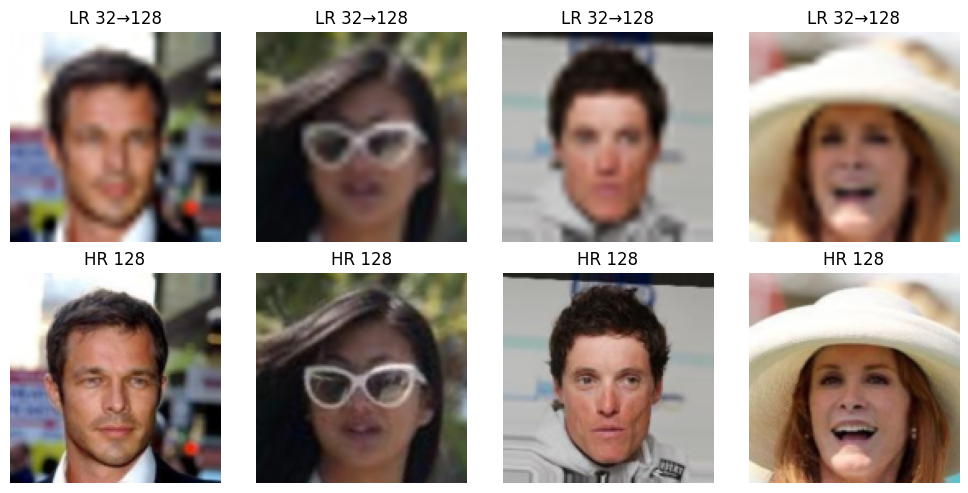

In [12]:
# 4. Inspect the actual paired data before training
x0_preview, x1_preview = next(iter(val_loader))

fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for i in range(4):
    axes[0, i].imshow(x0_preview[i].permute(1, 2, 0))
    axes[0, i].set_title("LR 32→128")
    axes[1, i].imshow(x1_preview[i].permute(1, 2, 0))
    axes[1, i].set_title("HR 128")
    for r in range(2):
        axes[r, i].axis("off")
plt.tight_layout()
plt.show()

### 2) Models (wrapped around EDM's SongUnet (ddpm++))

## Models

To keep the run feasible in Colab, the EDM DDPM++ backbone is deliberately smaller than the large default configuration: 64 base channels, four resolution levels, two residual blocks per level, and no attention blocks. This is an architecture baseline, not a pretrained EDM model. If GPU memory is tight, lower the batch size to 8.

In [13]:
# 5. Compact DDPM++ / SongUNet wrappers
# RESOLUTION = 64
# MODEL_CHANNELS = 64
# CHANNEL_MULT = [1, 2, 2, 2]
# NUM_BLOCKS = 2

# More efficient DDPM++
RESOLUTION = 128
MODEL_CHANNELS = 128
CHANNEL_MULT = [1, 2, 2, 2]
NUM_BLOCKS = 4


def make_songunet(in_channels, out_channels):
    return SongUNet(
        img_resolution=RESOLUTION,
        in_channels=in_channels,
        out_channels=out_channels,
        label_dim=0,
        augment_dim=0,
        model_channels=MODEL_CHANNELS,
        channel_mult=CHANNEL_MULT,
        num_blocks=NUM_BLOCKS,
        attn_resolutions=[16],      # for 1st pilot no -> add later
        dropout=0.0,
        embedding_type="positional",
        channel_mult_noise=1,
        encoder_type="standard",
        decoder_type="standard",
        resample_filter=[1, 1],
    )

In [14]:
class CelebAConditionalGenerator(nn.Module):
    # Deterministic residual generator: G(x) = x + R(x).
    def __init__(self):
        super().__init__()
        self.net = make_songunet(in_channels=3, out_channels=3)

    def forward(self, x0):
        labels = torch.ones(
            x0.shape[0], device=x0.device, dtype=torch.float32
        )
        residual = self.net(x0, noise_labels=labels, class_labels=None)
        return x0 + residual


class CelebAConditionalField(nn.Module):
    # f(t, y_tilde, x0) -> 3-channel displacement in target space.
    def __init__(self):
        super().__init__()
        self.net = make_songunet(in_channels=6, out_channels=3)

    def forward(self, t, x_tilde, x0):
        if x_tilde.shape != x0.shape:
            raise ValueError("x_tilde and x0 must have matching shapes")
        t = torch.as_tensor(t, device=x_tilde.device, dtype=torch.float32).reshape(-1)
        if t.numel() == 1:
            t = t.expand(x_tilde.shape[0])
        inp = torch.cat([x_tilde, x0], dim=1)
        return self.net(inp, noise_labels=t, class_labels=None)

In [ ]:
G = CelebAConditionalGenerator().to(device)
f = CelebAConditionalField().to(device)

print(f"G parameters: {sum(p.numel() for p in G.parameters()):,}")
print(f"f parameters: {sum(p.numel() for p in f.parameters()):,}")

# Shape and identity-init smoke test
with torch.no_grad():
    test_x = x0_preview[:2].to(device)
    test_y = G(test_x)
    test_t = torch.rand(2, device=device) * 0.5
    test_f = f(test_t, test_y, test_x)

print("G output:", tuple(test_y.shape), "| f output:", tuple(test_f.shape))
assert test_y.shape == test_x.shape and test_f.shape == test_x.shape

G parameters: 61,804,419
f parameters: 61,807,875
G output: (2, 3, 128, 128) | f output: (2, 3, 128, 128)


### 3) Losses -> training

##### 3.1) G and f losses; validation functions; time meter

In [ ]:
def mgm_loss_f(G, f, x_0, x_1, eps=0.01):
    N = x_0.shape[0]
    device = x_0.device

    # Generate the current reconstruction without gradients to G.
    with torch.no_grad():
        x_0_hat = G(x_0)

    if x_0_hat.shape != x_1.shape:
        raise ValueError(
            f"G(x_0) shape {x_0_hat.shape} must match "
            f"x_1 shape {x_1.shape}."
        )

    t = torch.rand(N, device=device) * 0.5
    t_img = t.view(N, 1, 1, 1)

    noise = torch.randn_like(x_0_hat)
    b = (
        torch.rand(N, 1, 1, 1, device=device) < 0.5
    ).float()

    # Symmetric interpolants.
    x_t = x_0_hat * (1.0 - t_img) + x_1 * t_img
    x_1mt = x_0_hat * t_img + x_1 * (1.0 - t_img)

    # Stochastic interpolant.
    sigma_t = torch.sqrt(eps * t_img * (1.0 - t_img))

    x_tilde = (
        (1.0 - b) * (x_t + noise * sigma_t)
        + b * (x_1mt + noise * sigma_t)
    )

    target = (x_1 - x_0_hat).detach()
    pred = f(t, x_tilde, x_0)

    if pred.shape != target.shape:
        raise ValueError(
            f"Field output {pred.shape} must match "
            f"displacement shape {target.shape}."
        )

    # Mean over pixels/channels per image, then batch mean.
    loss_f = (
        (pred.float() - target.float())
        .square()
        .flatten(1)
        .mean(dim=1)
        .mean()
    )

    return loss_f


# =====================================================================
# GENERATOR VARIATIONAL OBJECTIVE -> G
# =====================================================================
def mgm_loss_G(G, f, x_0, x_1, eps=0.01):
    N = x_0.shape[0]
    device = x_0.device

    x_0_hat = G(x_0)

    if x_0_hat.shape != x_1.shape:
        raise ValueError(
            f"G(x_0) shape {x_0_hat.shape} must match "
            f"x_1 shape {x_1.shape}."
        )

    t = torch.rand(N, device=device) * 0.5
    t_img = t.view(N, 1, 1, 1)

    noise = torch.randn_like(x_0_hat)
    b = (
        torch.rand(N, 1, 1, 1, device=device) < 0.5
    ).float()

    x_t = x_0_hat * (1.0 - t_img) + x_1 * t_img
    x_1mt = x_0_hat * t_img + x_1 * (1.0 - t_img)

    sigma_t = torch.sqrt(eps * t_img * (1.0 - t_img))

    x_tilde = (
        (1.0 - b) * (x_t + noise * sigma_t)
        + b * (x_1mt + noise * sigma_t)
    )

    # Keep gradients through x_0_hat and the field's input.
    drift = f(t, x_tilde, x_0)
    target = x_1 - x_0_hat

    if drift.shape != target.shape:
        raise ValueError(
            f"Field output {drift.shape} must match "
            f"displacement shape {target.shape}."
        )

    drift = drift.float()
    target = target.float()

    # MGM variational maximization objective.
    objective_g = (
        drift * (2.0 * target - drift)
    ).flatten(1).mean(dim=1).mean()

    return objective_g, x_0_hat

In [ ]:
@torch.no_grad()
def save_sample_grid(generator, val_loader, path, device, n_samples=4):
    generator_was_training = generator.training
    generator.eval()
    x0, x1 = next(iter(val_loader))
    x0 = x0[:n_samples].to(device)
    x1 = x1[:n_samples].to(device)
    pred = generator(x0).clamp(0, 1).cpu()
    x0, x1 = x0.cpu(), x1.cpu()

    fig, axes = plt.subplots(3, n_samples, figsize=(3*n_samples, 8))
    if n_samples == 1:
        axes = axes.reshape(3, 1)
    row_names = ["LR input (16→64)", "MGM prediction", "HR target"]
    for j in range(n_samples):
        for r, imgs in enumerate([x0, pred, x1]):
            axes[r, j].imshow(imgs[j].permute(1, 2, 0).numpy().clip(0, 1))
            axes[r, j].axis("off")
            if j == 0:
                axes[r, j].set_ylabel(row_names[r], fontsize=10)
    fig.tight_layout()
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=160, bbox_inches="tight")
    plt.show() # uncomment to draw in .ipynb instantly
    plt.close(fig)
    generator.train(generator_was_training)

In [ ]:
# Validation func -> MAE, MSE, SSIM, PSNR, % pixels out of [0, 1]
from torchmetrics.image import (
    StructuralSimilarityIndexMeasure,
    PeakSignalNoiseRatio,
)

@torch.no_grad()
def validate_mgm_celeba(
    generator,
    dataloader,
    device,
    max_batches=None,
):
    was_training = generator.training
    generator.eval()

    ssim_metric = StructuralSimilarityIndexMeasure(
        data_range=1.0
    ).to(device)

    psnr_metric = PeakSignalNoiseRatio(
        data_range=1.0
    ).to(device)

    sum_l1 = 0.0
    sum_mse = 0.0
    sum_outside = 0.0
    n_images = 0

    try:
        for batch_idx, (x_0, x_1) in enumerate(dataloader):
            if max_batches is not None and batch_idx >= max_batches:
                break

            x_0 = x_0.to(device, dtype=torch.float32, non_blocking=True)
            x_1 = x_1.to(device, dtype=torch.float32, non_blocking=True)

            pred = generator(x_0).float()

            if pred.shape != x_1.shape:
                raise ValueError(
                    f"Prediction shape {tuple(pred.shape)} != "
                    f"target shape {tuple(x_1.shape)}"
                )

            batch_n = x_1.shape[0]

            # Monitor raw model outputs before clamping.
            sum_outside += (
                ((pred < 0) | (pred > 1))
                .float()
                .mean()
                .item() * batch_n
            )

            # Metrics on valid image range [0, 1].
            pred_clamped = pred.clamp(0.0, 1.0)

            sum_l1 += (
                (pred_clamped - x_1).abs().mean().item() * batch_n
            )
            sum_mse += (
                (pred_clamped - x_1).square().mean().item() * batch_n
            )

            ssim_metric.update(pred_clamped, x_1)
            psnr_metric.update(pred_clamped, x_1)

            n_images += batch_n

        if n_images == 0:
            raise ValueError("Validation loader produced no images.")

        metrics = {
            "val_l1": sum_l1 / n_images,
            "val_mse": sum_mse / n_images,
            "val_ssim": ssim_metric.compute().item(),
            "val_psnr": psnr_metric.compute().item(),
            "val_outside_fraction": sum_outside / n_images,
        }

        return metrics

    finally:
        generator.train(was_training)
        ssim_metric.reset()
        psnr_metric.reset()

In [ ]:
class TimeMeter:
    def __init__(self, device):
        self.device = torch.device(device)
        self.wall_start = time.perf_counter()
        self.gpu_seconds = 0.0
        self.start_event = None
        self.end_event = None

        if self.device.type == "cuda":
            torch.cuda.synchronize(self.device)
            self.start_event = torch.cuda.Event(enable_timing=True)
            self.end_event = torch.cuda.Event(enable_timing=True)
            self.start_event.record()

    def finish(self):
        wall_seconds = time.perf_counter() - self.wall_start

        if self.device.type == "cuda":
            self.end_event.record()
            torch.cuda.synchronize(self.device)
            self.gpu_seconds = self.start_event.elapsed_time(
                self.end_event
            ) / 1000.0

        return {
            "wall_hours": wall_seconds / 3600,
            "gpu_hours": self.gpu_seconds / 3600,
            "gpu_seconds": self.gpu_seconds,
        }

##### 3.2) Training proceure

## Training

The alternating MGM update is kept structurally close to your existing training function. The main changes are:
- `validation_every`: validate every N epochs instead of every epoch.
- `checkpoint_every`: save a full resumable checkpoint every N epochs.
- `SAMPLES_PATH`: save a three-row, four-column sample PNG at initialization and at every checkpoint.
- Checkpoints include both networks, EMA generator, optimizer states, history, config, epoch, and global step.

The proposed first run is 10 epochs with 20k train images. Given the large EDM backbone, first watch GPU memory and epoch duration; reduce batch size if needed. Do not assume 10 epochs guarantees convergence.

In [ ]:
# =====================================================================
# TRAINING FUNCTION — CELEBA CONDITIONAL MGM
# Preserves the existing MNIST update convention and loss functions.
# =====================================================================
def train_mgm(
    generator,
    field,
    dataloader,
    epochs=10,
    lr_g=1e-5,
    lr_f=1e-5,
    lambda_l1=0.0,
    eps=0.01,
    device="cuda",
    max_grad_norm=1.0,
    ema_decay=0.999,
    k_critic_steps=1,
    val_dataloader=None,
    val_max_batches=None,
    checkpoint=None,
    f_warmup_checkpoint=None,
    checkpoint_dir=None,
    checkpoint_every=5,
    sample_fn=None,
    sample_every=5,
):
    import copy
    from pathlib import Path
    import torch
    import torch.nn.functional as F

    if eps < 0:
        raise ValueError("eps must be nonnegative.")
    if not isinstance(k_critic_steps, int) or k_critic_steps < 1:
        raise ValueError("k_critic_steps must be an integer >= 1.")
    if lambda_l1 < 0:
        raise ValueError("lambda_l1 must be nonnegative.")
    if not 0.0 <= ema_decay < 1.0:
        raise ValueError("ema_decay must be in [0, 1).")
    if len(dataloader) < 2:
        raise ValueError("Need at least two batches per epoch.")
    if checkpoint_every < 1:
        raise ValueError("checkpoint_every must be >= 1.")
    if sample_every < 1:
        raise ValueError("sample_every must be >= 1.")

    device = torch.device(device)

    generator = generator.to(device=device, dtype=torch.float32)
    field = field.to(device=device, dtype=torch.float32)

    opt_g = torch.optim.Adam(
        generator.parameters(), lr=lr_g, betas=(0.0, 0.999)
    )
    opt_f = torch.optim.Adam(
        field.parameters(), lr=lr_f, betas=(0.0, 0.999)
    )

    generator_ema = copy.deepcopy(generator).eval()
    generator_ema.requires_grad_(False)

    history = []
    start_epoch = 0
    global_step = 0

    # ---------------------------------------------------------------
    # Resume checkpoint
    # ---------------------------------------------------------------
    if checkpoint is not None:
        generator.load_state_dict(checkpoint["generator_state_dict"])
        generator_ema.load_state_dict(
            checkpoint["generator_ema_state_dict"]
        )
        field.load_state_dict(checkpoint["field_state_dict"])

        if "optimizer_g_state_dict" in checkpoint:
            opt_g.load_state_dict(checkpoint["optimizer_g_state_dict"])
        if "optimizer_f_state_dict" in checkpoint:
            opt_f.load_state_dict(checkpoint["optimizer_f_state_dict"])

        history = list(checkpoint.get("history", []))
        if history:
            start_epoch = history[-1]["epoch"]
            global_step = history[-1]["global_step"]
        else:
            start_epoch = checkpoint.get("epoch", 0)
            global_step = checkpoint.get("global_step", 0)

        print(
            f"Resuming after epoch {start_epoch}; "
            f"global_step={global_step}"
        )
    # ---------------------------------------------------------------
    # No checkpopint -> look for warmed-up field
    # ---------------------------------------------------------------
    elif f_warmup_checkpoint is not None:
        field.load_state_dict(f_warmup_checkpoint["field_state_dict"])
        opt_f.load_state_dict(f_warmup_checkpoint["optimizer_f_state_dict"])
        warmup_iters = f_warmup_checkpoint.get("global_step", 0)
        print(
            f"MGM training after critic (f) warmup for {warmup_iters} iterations;"
        )

    if checkpoint_dir is not None:
        checkpoint_dir = Path(checkpoint_dir)
        checkpoint_dir.mkdir(parents=True, exist_ok=True)

    total_epochs = start_epoch + epochs
    updates_per_epoch = len(dataloader) // (1 + k_critic_steps)

    print(
        f"Training conditional MGM | epochs {start_epoch + 1}"
        f"–{total_epochs} | paired updates/epoch: {updates_per_epoch}"
    )
    print(
        "Generator objective: mgm_loss_G returned value "
        "(preserving existing training convention)."
    )

    for epoch_idx in range(epochs):
        epoch = start_epoch + epoch_idx + 1
        generator.train()
        field.train()

        sum_loss_f = 0.0
        sum_loss_mgm = 0.0
        sum_loss_l1 = 0.0
        sum_loss_g = 0.0
        n_updates = 0

        batch_iterator = iter(dataloader)

        for batch_idx in tqdm(range(updates_per_epoch)):
            # -------------------------------------------------------
            # 1. k field updates, each using a fresh batch
            # -------------------------------------------------------
            cycle_loss_f = 0.0
            cycle_grad_f = 0.0

            for _ in range(k_critic_steps):
                x_0, x_1 = next(batch_iterator)
                x_0 = x_0.to(device=device, dtype=torch.float32)
                x_1 = x_1.to(device=device, dtype=torch.float32)

                field.requires_grad_(True)
                opt_f.zero_grad(set_to_none=True)

                loss_f = mgm_loss_f(
                    generator, field, x_0, x_1, eps=eps
                )

                if not torch.isfinite(loss_f):
                    raise RuntimeError("Non-finite field loss.")

                loss_f.backward()

                if max_grad_norm is not None:
                    grad_norm_f = torch.nn.utils.clip_grad_norm_(
                        field.parameters(),
                        max_norm=max_grad_norm,
                        error_if_nonfinite=True,
                    ).item()
                else:
                    grad_norm_f = float("nan")

                opt_f.step()

                cycle_loss_f += loss_f.item()
                cycle_grad_f += grad_norm_f

                opt_f.zero_grad(set_to_none=True)
                del x_0, x_1, loss_f

            mean_loss_f = cycle_loss_f / k_critic_steps
            mean_grad_f = cycle_grad_f / k_critic_steps

            # -------------------------------------------------------
            # 2. One generator update on a fresh batch
            # -------------------------------------------------------
            x_0, x_1 = next(batch_iterator)
            x_0 = x_0.to(device=device, dtype=torch.float32)
            x_1 = x_1.to(device=device, dtype=torch.float32)

            field.requires_grad_(False)
            opt_g.zero_grad(set_to_none=True)

            try:
                loss_mgm, x_0_hat = mgm_loss_G(
                    generator, field, x_0, x_1, eps=eps
                )

                if lambda_l1 > 0:
                    loss_l1 = F.l1_loss(x_0_hat, x_1)
                    loss_g = loss_mgm + lambda_l1 * loss_l1
                else:
                    with torch.no_grad():
                        loss_l1 = F.l1_loss(x_0_hat, x_1)
                    loss_g = loss_mgm

                if not torch.isfinite(loss_g):
                    raise RuntimeError("Non-finite generator loss.")

                loss_g.backward()

                if max_grad_norm is not None:
                    grad_norm_g = torch.nn.utils.clip_grad_norm_(
                        generator.parameters(),
                        max_norm=max_grad_norm,
                        error_if_nonfinite=True,
                    ).item()
                else:
                    grad_norm_g = float("nan")

                opt_g.step()

            finally:
                field.requires_grad_(True)

            # -------------------------------------------------------
            # 3. Update EMA once per generator update
            # -------------------------------------------------------
            with torch.no_grad():
                for p_ema, p in zip(
                    generator_ema.parameters(), generator.parameters()
                ):
                    p_ema.mul_(ema_decay).add_(p, alpha=1.0 - ema_decay)

                for b_ema, b in zip(
                    generator_ema.buffers(), generator.buffers()
                ):
                    b_ema.copy_(b)

            # global_step = completed MGM cycles / generator updates
            global_step += 1
            n_updates += 1

            sum_loss_f += mean_loss_f
            sum_loss_mgm += loss_mgm.item()
            sum_loss_l1 += loss_l1.item()
            sum_loss_g += loss_g.item()

            if batch_idx % 50 == 0:
                print(
                    f"Epoch {epoch}/{total_epochs} | "
                    f"cycle {batch_idx + 1}/{updates_per_epoch} | "
                    f"global_step={global_step} | "
                    f"F_mean={mean_loss_f:.5f} "
                    f"MGM={loss_mgm.item():.5f} "
                    f"L1={loss_l1.item():.5f} | "
                    f"Grad_F_mean={mean_grad_f:.3f} "
                    f"Grad_G={grad_norm_g:.3f}"
                )

            del x_0, x_1, x_0_hat, loss_mgm, loss_l1, loss_g

        row = {
            "epoch": epoch,
            "global_step": global_step,
            "loss_f": sum_loss_f / n_updates,   # sum of means over k update steps
            "loss_mgm": sum_loss_mgm / n_updates,
            "loss_l1": sum_loss_l1 / n_updates,
            "loss_g": sum_loss_g / n_updates,
        }

        # -----------------------------------------------------------
        # Validation using EMA generator
        # -----------------------------------------------------------
        if val_dataloader is not None:
            metrics = validate_mgm_celeba(
                generator_ema,
                val_dataloader,
                device,
                max_batches=val_max_batches,
            )
            row.update(metrics)

            print(
                f"EMA validation | "
                f"L1={row['val_l1']:.6f} | "
                f"MSE={row['val_mse']:.6f} | "
                f"SSIM={row['val_ssim']:.4f} | "
                f"PSNR={row['val_psnr']:.2f} dB | "
                f"outside [0,1]="
                f"{100 * row['val_outside_fraction']:.2f}%"
            )

        history.append(row)

        # -----------------------------------------------------------
        # Save sample grid silently, if requested
        # -----------------------------------------------------------
        if sample_fn is not None and epoch % sample_every == 0:
            sample_fn(generator_ema, epoch)

        # -----------------------------------------------------------
        # Save resumable checkpoint
        # -----------------------------------------------------------
        if (
            checkpoint_dir is not None
            and epoch % checkpoint_every == 0
        ):
            state = {
                "epoch": epoch,
                "global_step": global_step,
                "generator_state_dict": generator.state_dict(),
                "generator_ema_state_dict": generator_ema.state_dict(),
                "field_state_dict": field.state_dict(),
                "optimizer_g_state_dict": opt_g.state_dict(),
                "optimizer_f_state_dict": opt_f.state_dict(),
                "history": history,
                "config": {
                    "lr_g": lr_g,
                    "lr_f": lr_f,
                    "lambda_l1": lambda_l1,
                    "eps": eps,
                    "ema_decay": ema_decay,
                    "k_critic_steps": k_critic_steps,
                    "global_step_definition": "completed MGM cycles / generator updates",
                    "warmup_field_updates": (
                        f_warmup_checkpoint.get("global_step", 0)
                        if f_warmup_checkpoint is not None
                        else 0
                    ),
                },
            }

            path = checkpoint_dir / f"checkpoint_epoch_{epoch:04d}.pt"
            torch.save(state, path)
            print(f"Saved checkpoint: {path}")

    return generator, generator_ema, opt_g, opt_f, history

Training conditional MGM | epochs 1–15 | paired updates/epoch: 625
Generator objective: mgm_loss_G returned value (preserving existing training convention).


  0%|          | 0/625 [00:00<?, ?it/s]

Epoch 1/15 | update 1/625 | F=0.00266 MGM=0.00001 L1=0.03297 | Grad_F=0.071 Grad_G=0.086
Epoch 1/15 | update 51/625 | F=0.00446 MGM=0.00010 L1=0.03953 | Grad_F=0.055 Grad_G=0.030
Epoch 1/15 | update 101/625 | F=0.00377 MGM=0.00004 L1=0.03584 | Grad_F=0.035 Grad_G=0.012
Epoch 1/15 | update 151/625 | F=0.00323 MGM=0.00000 L1=0.03232 | Grad_F=0.026 Grad_G=0.007
Epoch 1/15 | update 201/625 | F=0.00360 MGM=0.00003 L1=0.03408 | Grad_F=0.048 Grad_G=0.012
Epoch 1/15 | update 251/625 | F=0.00288 MGM=0.00002 L1=0.03306 | Grad_F=0.035 Grad_G=0.010
Epoch 1/15 | update 301/625 | F=0.00368 MGM=0.00002 L1=0.03636 | Grad_F=0.048 Grad_G=0.015
Epoch 1/15 | update 351/625 | F=0.00339 MGM=0.00001 L1=0.03456 | Grad_F=0.024 Grad_G=0.008
Epoch 1/15 | update 401/625 | F=0.00244 MGM=0.00003 L1=0.02813 | Grad_F=0.015 Grad_G=0.009
Epoch 1/15 | update 451/625 | F=0.00233 MGM=0.00002 L1=0.03115 | Grad_F=0.040 Grad_G=0.012
Epoch 1/15 | update 501/625 | F=0.00262 MGM=0.00002 L1=0.03162 | Grad_F=0.023 Grad_G=0.005
Ep

  0%|          | 0/625 [00:00<?, ?it/s]

Epoch 2/15 | update 1/625 | F=0.00227 MGM=0.00002 L1=0.02800 | Grad_F=0.030 Grad_G=0.009
Epoch 2/15 | update 51/625 | F=0.00280 MGM=0.00003 L1=0.03466 | Grad_F=0.019 Grad_G=0.008
Epoch 2/15 | update 101/625 | F=0.00299 MGM=0.00004 L1=0.03257 | Grad_F=0.018 Grad_G=0.010
Epoch 2/15 | update 151/625 | F=0.00245 MGM=0.00002 L1=0.03030 | Grad_F=0.016 Grad_G=0.006
Epoch 2/15 | update 201/625 | F=0.00223 MGM=0.00001 L1=0.02833 | Grad_F=0.019 Grad_G=0.006
Epoch 2/15 | update 251/625 | F=0.00230 MGM=0.00002 L1=0.03213 | Grad_F=0.014 Grad_G=0.006
Epoch 2/15 | update 301/625 | F=0.00244 MGM=0.00001 L1=0.02531 | Grad_F=0.011 Grad_G=0.002
Epoch 2/15 | update 351/625 | F=0.00288 MGM=0.00002 L1=0.03048 | Grad_F=0.008 Grad_G=0.003
Epoch 2/15 | update 401/625 | F=0.00233 MGM=0.00001 L1=0.02580 | Grad_F=0.011 Grad_G=0.004
Epoch 2/15 | update 451/625 | F=0.00263 MGM=0.00001 L1=0.02772 | Grad_F=0.011 Grad_G=0.004
Epoch 2/15 | update 501/625 | F=0.00242 MGM=0.00002 L1=0.03028 | Grad_F=0.020 Grad_G=0.007
Ep

...

Epoch 3/15 | update 1/625 | F=0.00250 MGM=0.00000 L1=0.02992 | Grad_F=0.005 Grad_G=0.002
Epoch 3/15 | update 51/625 | F=0.00231 MGM=0.00000 L1=0.02964 | Grad_F=0.011 Grad_G=0.004
Epoch 3/15 | update 101/625 | F=0.00209 MGM=0.00001 L1=0.02788 | Grad_F=0.021 Grad_G=0.009
Epoch 3/15 | update 151/625 | F=0.00194 MGM=0.00001 L1=0.02768 | Grad_F=0.007 Grad_G=0.003
Epoch 3/15 | update 201/625 | F=0.00236 MGM=0.00001 L1=0.02839 | Grad_F=0.012 Grad_G=0.005
Epoch 3/15 | update 251/625 | F=0.00293 MGM=0.00001 L1=0.03043 | Grad_F=0.007 Grad_G=0.004
Epoch 3/15 | update 301/625 | F=0.00250 MGM=0.00001 L1=0.03053 | Grad_F=0.012 Grad_G=0.004
Epoch 3/15 | update 351/625 | F=0.00236 MGM=0.00001 L1=0.02924 | Grad_F=0.012 Grad_G=0.007
Epoch 3/15 | update 401/625 | F=0.00295 MGM=0.00001 L1=0.02922 | Grad_F=0.014 Grad_G=0.006
Epoch 3/15 | update 451/625 | F=0.00194 MGM=0.00002 L1=0.02856 | Grad_F=0.012 Grad_G=0.005
Epoch 3/15 | update 501/625 | F=0.00305 MGM=0.00001 L1=0.03259 | Grad_F=0.011 Grad_G=0.003
Ep

  0%|          | 0/625 [00:00<?, ?it/s]

Epoch 4/15 | update 1/625 | F=0.00249 MGM=0.00000 L1=0.02748 | Grad_F=0.005 Grad_G=0.002
Epoch 4/15 | update 51/625 | F=0.00208 MGM=0.00001 L1=0.02418 | Grad_F=0.004 Grad_G=0.001
Epoch 4/15 | update 101/625 | F=0.00252 MGM=0.00001 L1=0.03245 | Grad_F=0.011 Grad_G=0.003
Epoch 4/15 | update 151/625 | F=0.00238 MGM=0.00001 L1=0.02662 | Grad_F=0.006 Grad_G=0.002
Epoch 4/15 | update 201/625 | F=0.00220 MGM=0.00001 L1=0.02777 | Grad_F=0.006 Grad_G=0.003
Epoch 4/15 | update 251/625 | F=0.00201 MGM=0.00001 L1=0.02717 | Grad_F=0.004 Grad_G=0.002
Epoch 4/15 | update 301/625 | F=0.00210 MGM=0.00001 L1=0.02816 | Grad_F=0.008 Grad_G=0.002
Epoch 4/15 | update 351/625 | F=0.00206 MGM=0.00001 L1=0.02504 | Grad_F=0.007 Grad_G=0.002
Epoch 4/15 | update 401/625 | F=0.00219 MGM=0.00001 L1=0.02723 | Grad_F=0.010 Grad_G=0.005
Epoch 4/15 | update 451/625 | F=0.00247 MGM=0.00001 L1=0.02671 | Grad_F=0.007 Grad_G=0.003
Epoch 4/15 | update 501/625 | F=0.00246 MGM=0.00001 L1=0.03358 | Grad_F=0.009 Grad_G=0.002
Ep

  0%|          | 0/625 [00:00<?, ?it/s]

Epoch 5/15 | update 1/625 | F=0.00231 MGM=0.00001 L1=0.02901 | Grad_F=0.006 Grad_G=0.003
Epoch 5/15 | update 51/625 | F=0.00189 MGM=0.00001 L1=0.02858 | Grad_F=0.012 Grad_G=0.004
Epoch 5/15 | update 101/625 | F=0.00213 MGM=0.00001 L1=0.03268 | Grad_F=0.008 Grad_G=0.003
Epoch 5/15 | update 151/625 | F=0.00191 MGM=0.00000 L1=0.02547 | Grad_F=0.005 Grad_G=0.002
Epoch 5/15 | update 201/625 | F=0.00217 MGM=0.00001 L1=0.02915 | Grad_F=0.008 Grad_G=0.003
Epoch 5/15 | update 251/625 | F=0.00204 MGM=0.00001 L1=0.02668 | Grad_F=0.006 Grad_G=0.002
Epoch 5/15 | update 301/625 | F=0.00243 MGM=0.00001 L1=0.02620 | Grad_F=0.007 Grad_G=0.003
Epoch 5/15 | update 351/625 | F=0.00268 MGM=0.00001 L1=0.03004 | Grad_F=0.006 Grad_G=0.003
Epoch 5/15 | update 401/625 | F=0.00180 MGM=0.00001 L1=0.02798 | Grad_F=0.015 Grad_G=0.004
Epoch 5/15 | update 451/625 | F=0.00219 MGM=-0.00000 L1=0.02845 | Grad_F=0.004 Grad_G=0.003
Epoch 5/15 | update 501/625 | F=0.00292 MGM=0.00001 L1=0.02967 | Grad_F=0.005 Grad_G=0.002
E

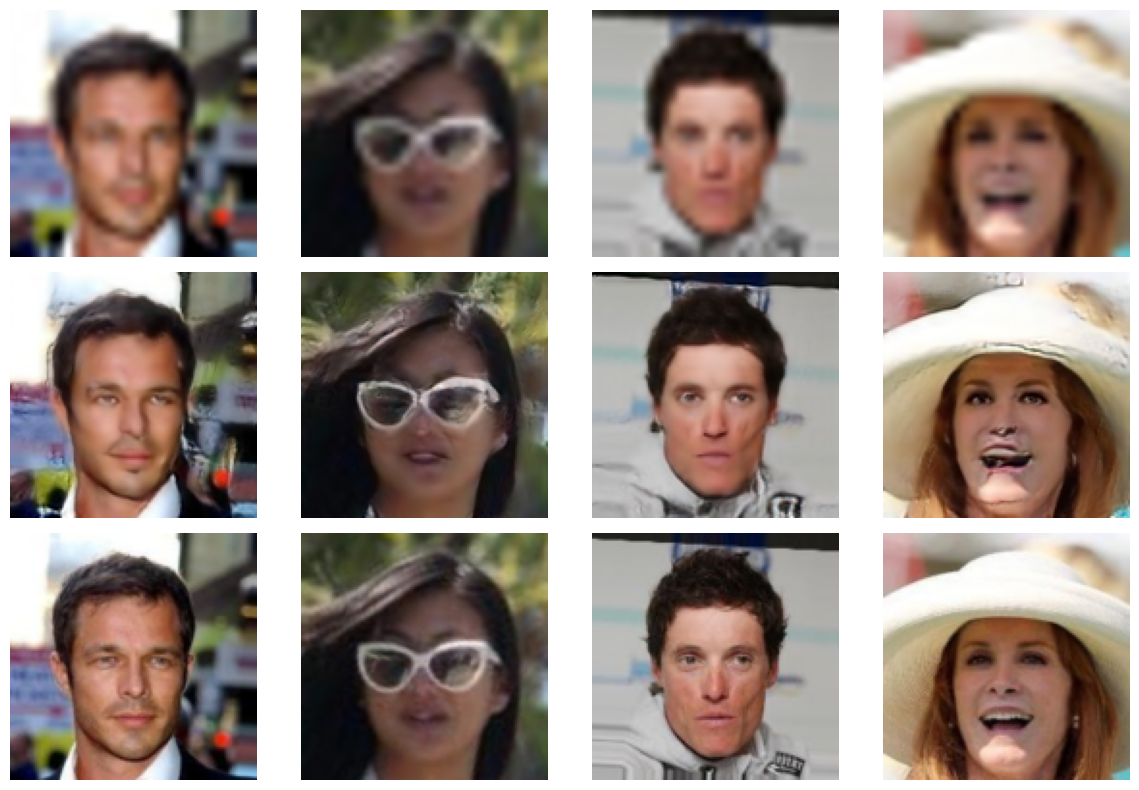

Saved checkpoint: /content/drive/MyDrive/AI_Notebooks/MGM/checkpoints/celeba_mgm_16to64/checkpoint_epoch_0005.pt


  0%|          | 0/625 [00:00<?, ?it/s]

Epoch 6/15 | update 1/625 | F=0.00626 MGM=0.00012 L1=0.04392 | Grad_F=0.057 Grad_G=0.059
Epoch 6/15 | update 51/625 | F=0.00265 MGM=0.00003 L1=0.03424 | Grad_F=0.007 Grad_G=0.007
Epoch 6/15 | update 101/625 | F=0.00232 MGM=0.00002 L1=0.02659 | Grad_F=0.008 Grad_G=0.004
Epoch 6/15 | update 151/625 | F=0.00205 MGM=0.00001 L1=0.02815 | Grad_F=0.005 Grad_G=0.002
Epoch 6/15 | update 201/625 | F=0.00236 MGM=0.00001 L1=0.02890 | Grad_F=0.005 Grad_G=0.005
Epoch 6/15 | update 251/625 | F=0.00266 MGM=0.00001 L1=0.03094 | Grad_F=0.005 Grad_G=0.002
Epoch 6/15 | update 301/625 | F=0.00239 MGM=0.00001 L1=0.02996 | Grad_F=0.003 Grad_G=0.001
Epoch 6/15 | update 351/625 | F=0.00288 MGM=0.00002 L1=0.03006 | Grad_F=0.004 Grad_G=0.004
Epoch 6/15 | update 401/625 | F=0.00245 MGM=0.00001 L1=0.03071 | Grad_F=0.003 Grad_G=0.003
Epoch 6/15 | update 451/625 | F=0.00207 MGM=0.00000 L1=0.02277 | Grad_F=0.008 Grad_G=0.003
Epoch 6/15 | update 501/625 | F=0.00209 MGM=0.00002 L1=0.02852 | Grad_F=0.016 Grad_G=0.005
Ep

  0%|          | 0/625 [00:00<?, ?it/s]

Epoch 7/15 | update 1/625 | F=0.00264 MGM=0.00001 L1=0.03070 | Grad_F=0.004 Grad_G=0.002
Epoch 7/15 | update 51/625 | F=0.00181 MGM=0.00001 L1=0.02847 | Grad_F=0.005 Grad_G=0.003
Epoch 7/15 | update 101/625 | F=0.00193 MGM=0.00000 L1=0.02848 | Grad_F=0.009 Grad_G=0.004
Epoch 7/15 | update 151/625 | F=0.00208 MGM=0.00001 L1=0.02873 | Grad_F=0.005 Grad_G=0.002
Epoch 7/15 | update 201/625 | F=0.00184 MGM=0.00002 L1=0.02701 | Grad_F=0.005 Grad_G=0.003
Epoch 7/15 | update 251/625 | F=0.00195 MGM=0.00001 L1=0.02619 | Grad_F=0.005 Grad_G=0.003
Epoch 7/15 | update 301/625 | F=0.00250 MGM=0.00001 L1=0.02952 | Grad_F=0.003 Grad_G=0.001
Epoch 7/15 | update 351/625 | F=0.00157 MGM=0.00000 L1=0.02599 | Grad_F=0.003 Grad_G=0.002
Epoch 7/15 | update 401/625 | F=0.00204 MGM=0.00000 L1=0.02405 | Grad_F=0.003 Grad_G=0.002
Epoch 7/15 | update 451/625 | F=0.00221 MGM=0.00000 L1=0.02533 | Grad_F=0.003 Grad_G=0.002
Epoch 7/15 | update 501/625 | F=0.00182 MGM=0.00000 L1=0.02535 | Grad_F=0.004 Grad_G=0.002
Ep

...

Epoch 8/15 | update 1/625 | F=0.00197 MGM=-0.00000 L1=0.02563 | Grad_F=0.005 Grad_G=0.001
Epoch 8/15 | update 51/625 | F=0.00163 MGM=0.00001 L1=0.02779 | Grad_F=0.004 Grad_G=0.003
Epoch 8/15 | update 101/625 | F=0.00200 MGM=0.00000 L1=0.02656 | Grad_F=0.002 Grad_G=0.001
Epoch 8/15 | update 151/625 | F=0.00185 MGM=0.00000 L1=0.02776 | Grad_F=0.003 Grad_G=0.002
Epoch 8/15 | update 201/625 | F=0.00202 MGM=0.00000 L1=0.02897 | Grad_F=0.002 Grad_G=0.002
Epoch 8/15 | update 251/625 | F=0.00268 MGM=0.00000 L1=0.03023 | Grad_F=0.003 Grad_G=0.002
Epoch 8/15 | update 301/625 | F=0.00176 MGM=0.00001 L1=0.02867 | Grad_F=0.003 Grad_G=0.002
Epoch 8/15 | update 351/625 | F=0.00151 MGM=0.00001 L1=0.02497 | Grad_F=0.006 Grad_G=0.002
Epoch 8/15 | update 401/625 | F=0.00322 MGM=0.00001 L1=0.03187 | Grad_F=0.004 Grad_G=0.003
Epoch 8/15 | update 451/625 | F=0.00198 MGM=0.00001 L1=0.02470 | Grad_F=0.005 Grad_G=0.002
Epoch 8/15 | update 501/625 | F=0.00164 MGM=0.00000 L1=0.02598 | Grad_F=0.003 Grad_G=0.001
E

  0%|          | 0/625 [00:00<?, ?it/s]

Epoch 9/15 | update 1/625 | F=0.00179 MGM=0.00000 L1=0.02718 | Grad_F=0.003 Grad_G=0.001
Epoch 9/15 | update 51/625 | F=0.00185 MGM=0.00001 L1=0.02937 | Grad_F=0.004 Grad_G=0.003
Epoch 9/15 | update 101/625 | F=0.00174 MGM=0.00000 L1=0.02716 | Grad_F=0.003 Grad_G=0.002
Epoch 9/15 | update 151/625 | F=0.00244 MGM=0.00000 L1=0.02570 | Grad_F=0.003 Grad_G=0.002
Epoch 9/15 | update 201/625 | F=0.00269 MGM=0.00001 L1=0.03202 | Grad_F=0.004 Grad_G=0.003
Epoch 9/15 | update 251/625 | F=0.00255 MGM=0.00001 L1=0.02670 | Grad_F=0.009 Grad_G=0.007
Epoch 9/15 | update 301/625 | F=0.00170 MGM=0.00000 L1=0.02882 | Grad_F=0.005 Grad_G=0.002
Epoch 9/15 | update 351/625 | F=0.00205 MGM=0.00000 L1=0.02911 | Grad_F=0.003 Grad_G=0.002
Epoch 9/15 | update 401/625 | F=0.00207 MGM=0.00000 L1=0.02737 | Grad_F=0.003 Grad_G=0.001
Epoch 9/15 | update 451/625 | F=0.00200 MGM=0.00000 L1=0.02870 | Grad_F=0.003 Grad_G=0.002
Epoch 9/15 | update 501/625 | F=0.00226 MGM=0.00000 L1=0.02755 | Grad_F=0.004 Grad_G=0.001
Ep

  0%|          | 0/625 [00:00<?, ?it/s]

Epoch 10/15 | update 1/625 | F=0.00176 MGM=0.00000 L1=0.02574 | Grad_F=0.003 Grad_G=0.001
Epoch 10/15 | update 51/625 | F=0.00200 MGM=0.00000 L1=0.02490 | Grad_F=0.005 Grad_G=0.004
Epoch 10/15 | update 101/625 | F=0.00302 MGM=0.00001 L1=0.03342 | Grad_F=0.007 Grad_G=0.004
Epoch 10/15 | update 151/625 | F=0.00159 MGM=0.00001 L1=0.02352 | Grad_F=0.005 Grad_G=0.003
Epoch 10/15 | update 201/625 | F=0.00222 MGM=0.00001 L1=0.02935 | Grad_F=0.003 Grad_G=0.001
Epoch 10/15 | update 251/625 | F=0.00233 MGM=0.00001 L1=0.02883 | Grad_F=0.003 Grad_G=0.002
Epoch 10/15 | update 301/625 | F=0.00263 MGM=0.00001 L1=0.03175 | Grad_F=0.005 Grad_G=0.003
Epoch 10/15 | update 351/625 | F=0.00209 MGM=0.00001 L1=0.02974 | Grad_F=0.003 Grad_G=0.002
Epoch 10/15 | update 401/625 | F=0.00174 MGM=0.00000 L1=0.02610 | Grad_F=0.003 Grad_G=0.002
Epoch 10/15 | update 451/625 | F=0.00251 MGM=0.00000 L1=0.02795 | Grad_F=0.002 Grad_G=0.001
Epoch 10/15 | update 501/625 | F=0.00320 MGM=0.00000 L1=0.02989 | Grad_F=0.003 Grad

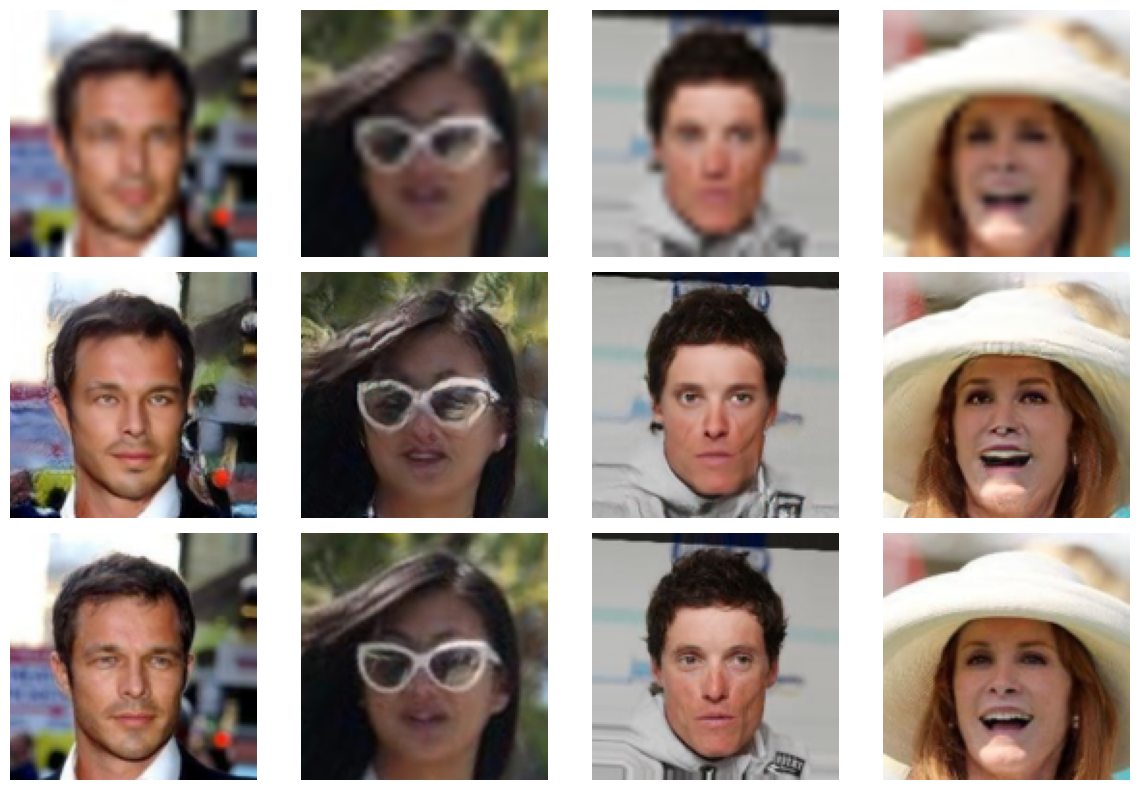

Saved checkpoint: /content/drive/MyDrive/AI_Notebooks/MGM/checkpoints/celeba_mgm_16to64/checkpoint_epoch_0010.pt


  0%|          | 0/625 [00:00<?, ?it/s]

Epoch 11/15 | update 1/625 | F=0.00319 MGM=0.00001 L1=0.03388 | Grad_F=0.004 Grad_G=0.003
Epoch 11/15 | update 51/625 | F=0.00184 MGM=0.00001 L1=0.02544 | Grad_F=0.002 Grad_G=0.002


KeyboardInterrupt: 

In [ ]:
EPOCHS = 15
LR_G = 1e-5
LR_F = 1e-5
LAMBDA_L1 = 0.0  # Pure MGM objective
EPS = 0.01

VALIDATION_EVERY = 5
CHECKPOINT_EVERY = 5

def sample_fn(generator_ema, epoch):
    save_sample_grid(
        generator=generator_ema,
        val_loader=val_loader,
        path=SAMPLES_PATH / f"celeba_epoch_{epoch:04d}.png",
        device=device,
        n_samples=4,
    )

meter = TimeMeter(device)

G, G_ema, opt_g, opt_f, history = train_mgm(
    generator=G,
    field=f,
    dataloader=train_loader,
    epochs=EPOCHS,
    lr_g=LR_G,
    lr_f=LR_F,
    lambda_l1=LAMBDA_L1,
    eps=EPS,
    device=device,
    max_grad_norm=1.0,
    ema_decay=0.999,
    val_dataloader=val_loader,
    val_max_batches=None,  # Full validation set
    checkpoint_dir=CHECKPOINTS_PATH,
    checkpoint_every=CHECKPOINT_EVERY,
    sample_fn=sample_fn,
    sample_every=VALIDATION_EVERY,
)

# Preserve the trained field variable for later notebook cells.
f = f

cost = meter.finish()

print(f"\nCUDA-event hours: {cost['gpu_hours']:.4f}")
print(f"CUDA-event seconds: {cost['gpu_seconds']:.1f}")
print(f"Wall-clock hours: {cost['wall_hours']:.4f}")


In [ ]:
history_df = pd.DataFrame(history)
display(history_df)

,epoch,global_step,loss_f,loss_mgm,loss_l1,loss_g,val_l1,val_mse,val_outside_fraction
0,1,625,0.005351,0.000162,0.049610,0.000162,0.051753,0.005640,0.019928
1,2,1250,0.004745,0.000053,0.045561,0.000053,0.044938,0.004610,0.018468
2,3,1875,0.004489,0.000042,0.043885,0.000042,0.040647,0.004011,0.017737
3,4,2500,0.004437,0.000037,0.043203,0.000037,0.039156,0.003814,0.016859
4,5,3125,0.004364,0.000031,0.043028,0.000031,0.038723,0.003759,0.016197
5,6,3750,0.004319,0.000032,0.042329,0.000032,0.038331,0.003717,0.015251
6,7,4375,0.004312,0.000031,0.042422,0.000031,0.038029,0.003669,0.014623
7,8,5000,0.004220,0.000033,0.042009,0.000033,0.037694,0.003633,0.013934
8,9,5625,0.004185,0.000026,0.041932,0.000026,0.037372,0.003574,0.013507
9,10,6250,0.004153,0.000034,0.041530,0.000034,0.036961,0.003511,0.013211


In [ ]:
HISTORY_PATH = Path(CHECKPOINTS_PATH).parent / "histories"
HISTORY_PATH.mkdir(parents=True, exist_ok=True)

# Save as CSV
csv_path = HISTORY_PATH / "exp1_celeba_history.csv"
history_df.to_csv(csv_path, index=False)

print(f"History saved to:\n{csv_path}")
print(f"Recorded epochs: {len(history)}")
print("Recorded metrics:", list(history_df.columns))

History saved to:
/content/drive/MyDrive/AI_Notebooks/MGM/checkpoints/histories/exp1_celeba_history.csv
Recorded epochs: 10
Recorded metrics: ['epoch', 'global_step', 'loss_f', 'loss_mgm', 'loss_l1', 'loss_g', 'val_l1', 'val_mse', 'val_outside_fraction']


#### Training with warm-up

##### 1) Warming-up field critic (f)

In [ ]:
WARMUP_STEPS = 2000
LR_F = 1e-5
EPS = 0.01
MAX_GRAD_NORM = 1.0

# Keep this experiment separate from the original baseline.
WARMUP_CHECKPOINTS_PATH = (FOLDER_PATH / "checkpoints" / "celeba_f_warmup")
WARMUP_CHECKPOINTS_PATH.mkdir(parents=True, exist_ok=True)
WARMUP_CHECKPOINT_PATH = (WARMUP_CHECKPOINTS_PATH / "field_warmup_28t132_0500.pt")

# IMPORTANT: create fresh models for a clean warm-up experiment.
G = CelebAConditionalGenerator().to(device)
f = CelebAConditionalField().to(device)

# Keep G fixed; train only f.
G.eval()
G.requires_grad_(False)
f.train()
f.requires_grad_(True)

opt_f = torch.optim.Adam(
    f.parameters(),
    lr=LR_F,
    betas=(0.0, 0.999),
)

warmup_losses = []
batch_iterator = iter(train_loader)
# pbar = tqdm(range(WARMUP_STEPS), desc="Field warm-up", ncols=90)
meter = TimeMeter(device)

for warmup_step in tqdm(range(WARMUP_STEPS)):
    try:
        x_0, x_1 = next(batch_iterator)
    except StopIteration:
        batch_iterator = iter(train_loader)
        x_0, x_1 = next(batch_iterator)

    x_0 = x_0.to(device=device, dtype=torch.float32, non_blocking=True)
    x_1 = x_1.to(device=device, dtype=torch.float32, non_blocking=True)

    opt_f.zero_grad(set_to_none=True)

    # Uses your existing MGM field loss unchanged.
    loss_f = mgm_loss_f(G, f, x_0, x_1, eps=EPS)

    if not torch.isfinite(loss_f):
        raise RuntimeError(
            f"Non-finite field loss at warm-up step {warmup_step + 1}"
        )

    loss_f.backward()

    grad_norm_f = torch.nn.utils.clip_grad_norm_(
        f.parameters(),
        max_norm=MAX_GRAD_NORM,
        error_if_nonfinite=True,
    ).item()

    opt_f.step()

    warmup_losses.append(loss_f.item())

    if (warmup_step + 1) % 50 == 0:
        print(
            f"Step {warmup_step + 1}/{WARMUP_STEPS} | "
            f"F_loss={sum(warmup_losses[-50:]) / 50:.6f} | "
            f"Grad_F={grad_norm_f:.4f} "
        )

    del x_0, x_1, loss_f


cost = meter.finish()

print(f"\nCUDA-event hours: {cost['gpu_hours']:.4f}")
print(f"CUDA-event seconds: {cost['gpu_seconds']:.1f}")
print(f"Wall-clock hours: {cost['wall_hours']:.4f}")

# Save the warmed-up field AND its optimizer state.
warmup_checkpoint = {
    "phase": "field_only_warmup",
    "global_step": WARMUP_STEPS,  # field updates in warm-up phase
    "warmup_field_updates": WARMUP_STEPS,
    "field_state_dict": f.state_dict(),
    "optimizer_f_state_dict": opt_f.state_dict(),
    "mean_loss_f": sum(warmup_losses) / len(warmup_losses),
    "config": {
        "lr_f": LR_F,
        "eps": EPS,
        "max_grad_norm": MAX_GRAD_NORM,
        "warmup_steps": WARMUP_STEPS,
    },
}

torch.save(warmup_checkpoint, WARMUP_CHECKPOINT_PATH)

print(f"Warm-up complete: {WARMUP_STEPS} field updates")
print(f"Mean warm-up field loss: {warmup_checkpoint['mean_loss_f']:.6f}")
print(f"Saved warm-up checkpoint: {WARMUP_CHECKPOINT_PATH}")

  0%|          | 0/2000 [00:00<?, ?it/s]

Step 50/2000 | F_loss=0.001398 | Grad_F=0.0601 
Step 100/2000 | F_loss=0.000843 | Grad_F=0.0564 
Step 150/2000 | F_loss=0.000752 | Grad_F=0.0482 
Step 200/2000 | F_loss=0.000713 | Grad_F=0.0495 
Step 250/2000 | F_loss=0.000662 | Grad_F=0.0509 
Step 300/2000 | F_loss=0.000662 | Grad_F=0.0237 
Step 350/2000 | F_loss=0.000603 | Grad_F=0.0539 
Step 400/2000 | F_loss=0.000583 | Grad_F=0.0197 
Step 450/2000 | F_loss=0.000541 | Grad_F=0.0313 
Step 500/2000 | F_loss=0.000558 | Grad_F=0.0389 
Step 550/2000 | F_loss=0.000566 | Grad_F=0.0324 
Step 600/2000 | F_loss=0.000560 | Grad_F=0.0328 
Step 650/2000 | F_loss=0.000511 | Grad_F=0.0201 
Step 700/2000 | F_loss=0.000529 | Grad_F=0.0499 
Step 750/2000 | F_loss=0.000482 | Grad_F=0.0230 
Step 800/2000 | F_loss=0.000501 | Grad_F=0.0295 
Step 850/2000 | F_loss=0.000492 | Grad_F=0.0496 
Step 900/2000 | F_loss=0.000459 | Grad_F=0.0391 
Step 950/2000 | F_loss=0.000489 | Grad_F=0.0397 
Step 1000/2000 | F_loss=0.000494 | Grad_F=0.0324 
Step 1050/2000 | F_l

##### 2) Carry on joint training

In [ ]:
# Load warm-up checkpoint on CPU, then train_mgm restores its state.
warmup_checkpoint = torch.load(
    WARMUP_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False,
)

# Create fresh models
G = CelebAConditionalGenerator().to(device)
f = CelebAConditionalField().to(device)

MGM training after critic (f) warmup for 2000 iterations;
Training conditional MGM | epochs 1–10 | paired updates/epoch: 625
Generator objective: mgm_loss_G returned value (preserving existing training convention).


  0%|          | 0/625 [00:00<?, ?it/s]

Epoch 1/10 | cycle 1/625 | global_step=1 | F_mean=0.00042 MGM=0.00263 L1=0.03266 | Grad_F_mean=0.017 Grad_G=0.039
Epoch 1/10 | cycle 51/625 | global_step=51 | F_mean=0.00240 MGM=0.00060 L1=0.03048 | Grad_F_mean=0.070 Grad_G=0.039
Epoch 1/10 | cycle 101/625 | global_step=101 | F_mean=0.00205 MGM=0.00069 L1=0.03093 | Grad_F_mean=0.055 Grad_G=0.048
Epoch 1/10 | cycle 151/625 | global_step=151 | F_mean=0.00236 MGM=0.00035 L1=0.03346 | Grad_F_mean=0.194 Grad_G=0.067
Epoch 1/10 | cycle 201/625 | global_step=201 | F_mean=0.00200 MGM=0.00028 L1=0.02879 | Grad_F_mean=0.030 Grad_G=0.028
Epoch 1/10 | cycle 251/625 | global_step=251 | F_mean=0.00205 MGM=0.00037 L1=0.02834 | Grad_F_mean=0.053 Grad_G=0.035
Epoch 1/10 | cycle 301/625 | global_step=301 | F_mean=0.00145 MGM=0.00016 L1=0.02689 | Grad_F_mean=0.062 Grad_G=0.049
Epoch 1/10 | cycle 351/625 | global_step=351 | F_mean=0.00295 MGM=0.00021 L1=0.03278 | Grad_F_mean=0.029 Grad_G=0.032
Epoch 1/10 | cycle 401/625 | global_step=401 | F_mean=0.00237 

  0%|          | 0/625 [00:00<?, ?it/s]

Epoch 2/10 | cycle 1/625 | global_step=626 | F_mean=0.00209 MGM=0.00009 L1=0.02583 | Grad_F_mean=0.035 Grad_G=0.022
Epoch 2/10 | cycle 51/625 | global_step=676 | F_mean=0.00216 MGM=0.00004 L1=0.02531 | Grad_F_mean=0.023 Grad_G=0.009
Epoch 2/10 | cycle 101/625 | global_step=726 | F_mean=0.00206 MGM=0.00003 L1=0.02817 | Grad_F_mean=0.017 Grad_G=0.021
Epoch 2/10 | cycle 151/625 | global_step=776 | F_mean=0.00167 MGM=0.00005 L1=0.02704 | Grad_F_mean=0.030 Grad_G=0.016
Epoch 2/10 | cycle 201/625 | global_step=826 | F_mean=0.00282 MGM=0.00004 L1=0.02646 | Grad_F_mean=0.025 Grad_G=0.012
Epoch 2/10 | cycle 251/625 | global_step=876 | F_mean=0.00208 MGM=0.00006 L1=0.02850 | Grad_F_mean=0.014 Grad_G=0.021
Epoch 2/10 | cycle 301/625 | global_step=926 | F_mean=0.00224 MGM=0.00004 L1=0.02588 | Grad_F_mean=0.021 Grad_G=0.008
Epoch 2/10 | cycle 351/625 | global_step=976 | F_mean=0.00185 MGM=0.00003 L1=0.02662 | Grad_F_mean=0.012 Grad_G=0.010
Epoch 2/10 | cycle 401/625 | global_step=1026 | F_mean=0.00

...

Epoch 3/10 | cycle 1/625 | global_step=1251 | F_mean=0.00197 MGM=0.00007 L1=0.02833 | Grad_F_mean=0.020 Grad_G=0.012
Epoch 3/10 | cycle 51/625 | global_step=1301 | F_mean=0.00221 MGM=0.00002 L1=0.03044 | Grad_F_mean=0.021 Grad_G=0.011
Epoch 3/10 | cycle 101/625 | global_step=1351 | F_mean=0.00237 MGM=0.00002 L1=0.02528 | Grad_F_mean=0.025 Grad_G=0.012
Epoch 3/10 | cycle 151/625 | global_step=1401 | F_mean=0.00273 MGM=0.00003 L1=0.03339 | Grad_F_mean=0.053 Grad_G=0.021
Epoch 3/10 | cycle 201/625 | global_step=1451 | F_mean=0.00303 MGM=0.00006 L1=0.02953 | Grad_F_mean=0.026 Grad_G=0.013
Epoch 3/10 | cycle 251/625 | global_step=1501 | F_mean=0.00175 MGM=0.00002 L1=0.02518 | Grad_F_mean=0.014 Grad_G=0.006
Epoch 3/10 | cycle 301/625 | global_step=1551 | F_mean=0.00164 MGM=0.00007 L1=0.02650 | Grad_F_mean=0.035 Grad_G=0.022
Epoch 3/10 | cycle 351/625 | global_step=1601 | F_mean=0.00225 MGM=0.00005 L1=0.02669 | Grad_F_mean=0.183 Grad_G=0.063
Epoch 3/10 | cycle 401/625 | global_step=1651 | F_m

  0%|          | 0/625 [00:00<?, ?it/s]

Epoch 4/10 | cycle 1/625 | global_step=1876 | F_mean=0.00229 MGM=0.00001 L1=0.03100 | Grad_F_mean=0.007 Grad_G=0.003
Epoch 4/10 | cycle 51/625 | global_step=1926 | F_mean=0.00164 MGM=0.00003 L1=0.02800 | Grad_F_mean=0.013 Grad_G=0.004
Epoch 4/10 | cycle 101/625 | global_step=1976 | F_mean=0.00154 MGM=0.00002 L1=0.02601 | Grad_F_mean=0.009 Grad_G=0.005
Epoch 4/10 | cycle 151/625 | global_step=2026 | F_mean=0.00220 MGM=0.00001 L1=0.02420 | Grad_F_mean=0.014 Grad_G=0.006
Epoch 4/10 | cycle 201/625 | global_step=2076 | F_mean=0.00157 MGM=0.00006 L1=0.02413 | Grad_F_mean=0.045 Grad_G=0.019
Epoch 4/10 | cycle 251/625 | global_step=2126 | F_mean=0.00175 MGM=0.00003 L1=0.02712 | Grad_F_mean=0.019 Grad_G=0.012
Epoch 4/10 | cycle 301/625 | global_step=2176 | F_mean=0.00340 MGM=0.00013 L1=0.03487 | Grad_F_mean=0.021 Grad_G=0.017
Epoch 4/10 | cycle 351/625 | global_step=2226 | F_mean=0.00234 MGM=0.00002 L1=0.02592 | Grad_F_mean=0.027 Grad_G=0.009
Epoch 4/10 | cycle 401/625 | global_step=2276 | F_m

  0%|          | 0/625 [00:00<?, ?it/s]

Epoch 5/10 | cycle 1/625 | global_step=2501 | F_mean=0.00187 MGM=0.00004 L1=0.02622 | Grad_F_mean=0.079 Grad_G=0.040
Epoch 5/10 | cycle 51/625 | global_step=2551 | F_mean=0.00154 MGM=0.00003 L1=0.02286 | Grad_F_mean=0.012 Grad_G=0.004
Epoch 5/10 | cycle 101/625 | global_step=2601 | F_mean=0.00191 MGM=0.00002 L1=0.02356 | Grad_F_mean=0.010 Grad_G=0.004
Epoch 5/10 | cycle 151/625 | global_step=2651 | F_mean=0.00244 MGM=0.00004 L1=0.02994 | Grad_F_mean=0.014 Grad_G=0.008
Epoch 5/10 | cycle 201/625 | global_step=2701 | F_mean=0.00258 MGM=0.00006 L1=0.02991 | Grad_F_mean=0.010 Grad_G=0.006
Epoch 5/10 | cycle 251/625 | global_step=2751 | F_mean=0.00229 MGM=0.00004 L1=0.03055 | Grad_F_mean=0.013 Grad_G=0.008
Epoch 5/10 | cycle 301/625 | global_step=2801 | F_mean=0.00209 MGM=0.00001 L1=0.02522 | Grad_F_mean=0.008 Grad_G=0.003
Epoch 5/10 | cycle 351/625 | global_step=2851 | F_mean=0.00174 MGM=0.00001 L1=0.02618 | Grad_F_mean=0.016 Grad_G=0.005
Epoch 5/10 | cycle 401/625 | global_step=2901 | F_m

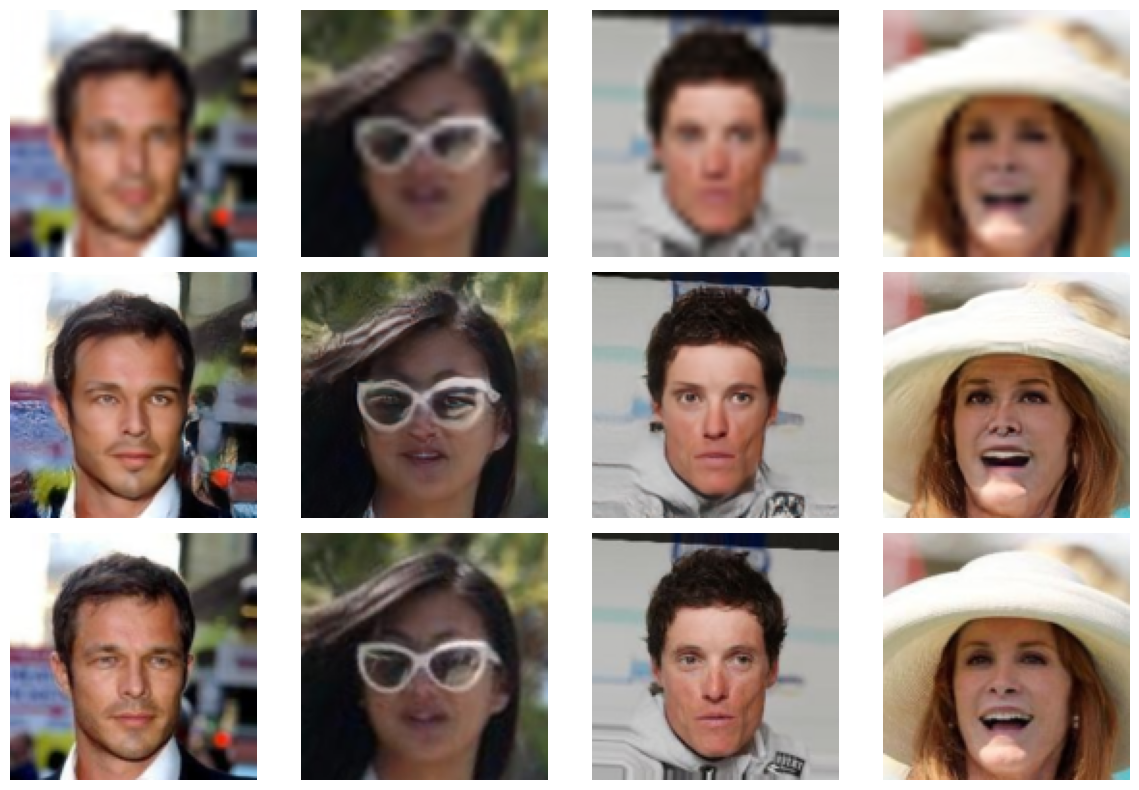

Saved checkpoint: /content/drive/MyDrive/AI_Notebooks/MGM/checkpoints/celeba_mgm_newexp/checkpoint_epoch_0005.pt


  0%|          | 0/625 [00:00<?, ?it/s]

Epoch 6/10 | cycle 1/625 | global_step=3126 | F_mean=0.00187 MGM=0.00003 L1=0.02594 | Grad_F_mean=0.008 Grad_G=0.004
Epoch 6/10 | cycle 51/625 | global_step=3176 | F_mean=0.00164 MGM=0.00001 L1=0.02444 | Grad_F_mean=0.008 Grad_G=0.005
Epoch 6/10 | cycle 101/625 | global_step=3226 | F_mean=0.00165 MGM=0.00000 L1=0.02606 | Grad_F_mean=0.009 Grad_G=0.004
Epoch 6/10 | cycle 151/625 | global_step=3276 | F_mean=0.00239 MGM=0.00001 L1=0.03147 | Grad_F_mean=0.004 Grad_G=0.005
Epoch 6/10 | cycle 201/625 | global_step=3326 | F_mean=0.00130 MGM=0.00003 L1=0.02520 | Grad_F_mean=0.013 Grad_G=0.008
Epoch 6/10 | cycle 251/625 | global_step=3376 | F_mean=0.00310 MGM=0.00001 L1=0.02908 | Grad_F_mean=0.004 Grad_G=0.003
Epoch 6/10 | cycle 301/625 | global_step=3426 | F_mean=0.00168 MGM=0.00001 L1=0.02609 | Grad_F_mean=0.005 Grad_G=0.004
Epoch 6/10 | cycle 351/625 | global_step=3476 | F_mean=0.00141 MGM=0.00004 L1=0.02569 | Grad_F_mean=0.006 Grad_G=0.006
Epoch 6/10 | cycle 401/625 | global_step=3526 | F_m

  0%|          | 0/625 [00:00<?, ?it/s]

Epoch 7/10 | cycle 1/625 | global_step=3751 | F_mean=0.00206 MGM=0.00001 L1=0.02738 | Grad_F_mean=0.005 Grad_G=0.005
Epoch 7/10 | cycle 51/625 | global_step=3801 | F_mean=0.00207 MGM=0.00002 L1=0.02764 | Grad_F_mean=0.006 Grad_G=0.003
Epoch 7/10 | cycle 101/625 | global_step=3851 | F_mean=0.00203 MGM=0.00002 L1=0.02904 | Grad_F_mean=0.007 Grad_G=0.005
Epoch 7/10 | cycle 151/625 | global_step=3901 | F_mean=0.00183 MGM=0.00000 L1=0.02587 | Grad_F_mean=0.005 Grad_G=0.003
Epoch 7/10 | cycle 201/625 | global_step=3951 | F_mean=0.00156 MGM=0.00001 L1=0.02520 | Grad_F_mean=0.008 Grad_G=0.004
Epoch 7/10 | cycle 251/625 | global_step=4001 | F_mean=0.00167 MGM=0.00000 L1=0.02609 | Grad_F_mean=0.004 Grad_G=0.002
Epoch 7/10 | cycle 301/625 | global_step=4051 | F_mean=0.00260 MGM=0.00002 L1=0.03062 | Grad_F_mean=0.008 Grad_G=0.008
Epoch 7/10 | cycle 351/625 | global_step=4101 | F_mean=0.00151 MGM=0.00001 L1=0.02333 | Grad_F_mean=0.007 Grad_G=0.003
Epoch 7/10 | cycle 401/625 | global_step=4151 | F_m

...

Epoch 8/10 | cycle 1/625 | global_step=4376 | F_mean=0.00188 MGM=0.00001 L1=0.02892 | Grad_F_mean=0.004 Grad_G=0.002
Epoch 8/10 | cycle 51/625 | global_step=4426 | F_mean=0.00178 MGM=0.00003 L1=0.02766 | Grad_F_mean=0.008 Grad_G=0.003
Epoch 8/10 | cycle 101/625 | global_step=4476 | F_mean=0.00171 MGM=0.00004 L1=0.02056 | Grad_F_mean=0.017 Grad_G=0.006
Epoch 8/10 | cycle 151/625 | global_step=4526 | F_mean=0.00214 MGM=0.00002 L1=0.02723 | Grad_F_mean=0.005 Grad_G=0.004
Epoch 8/10 | cycle 201/625 | global_step=4576 | F_mean=0.00194 MGM=0.00001 L1=0.02516 | Grad_F_mean=0.005 Grad_G=0.002
Epoch 8/10 | cycle 251/625 | global_step=4626 | F_mean=0.00184 MGM=0.00002 L1=0.02308 | Grad_F_mean=0.007 Grad_G=0.003
Epoch 8/10 | cycle 301/625 | global_step=4676 | F_mean=0.00184 MGM=0.00004 L1=0.02688 | Grad_F_mean=0.004 Grad_G=0.003
Epoch 8/10 | cycle 351/625 | global_step=4726 | F_mean=0.00146 MGM=0.00002 L1=0.02580 | Grad_F_mean=0.005 Grad_G=0.004
Epoch 8/10 | cycle 401/625 | global_step=4776 | F_m

  0%|          | 0/625 [00:00<?, ?it/s]

Epoch 9/10 | cycle 1/625 | global_step=5001 | F_mean=0.00353 MGM=0.00006 L1=0.03354 | Grad_F_mean=0.019 Grad_G=0.012
Epoch 9/10 | cycle 51/625 | global_step=5051 | F_mean=0.00207 MGM=0.00001 L1=0.02819 | Grad_F_mean=0.004 Grad_G=0.003
Epoch 9/10 | cycle 101/625 | global_step=5101 | F_mean=0.00259 MGM=0.00002 L1=0.03350 | Grad_F_mean=0.007 Grad_G=0.009
Epoch 9/10 | cycle 151/625 | global_step=5151 | F_mean=0.00274 MGM=0.00000 L1=0.02913 | Grad_F_mean=0.004 Grad_G=0.002
Epoch 9/10 | cycle 201/625 | global_step=5201 | F_mean=0.00170 MGM=0.00001 L1=0.02645 | Grad_F_mean=0.006 Grad_G=0.004
Epoch 9/10 | cycle 251/625 | global_step=5251 | F_mean=0.00137 MGM=0.00001 L1=0.02505 | Grad_F_mean=0.003 Grad_G=0.002
Epoch 9/10 | cycle 301/625 | global_step=5301 | F_mean=0.00215 MGM=0.00000 L1=0.02371 | Grad_F_mean=0.004 Grad_G=0.002
Epoch 9/10 | cycle 351/625 | global_step=5351 | F_mean=0.00277 MGM=0.00001 L1=0.02259 | Grad_F_mean=0.005 Grad_G=0.003
Epoch 9/10 | cycle 401/625 | global_step=5401 | F_m

  0%|          | 0/625 [00:00<?, ?it/s]

Epoch 10/10 | cycle 1/625 | global_step=5626 | F_mean=0.00217 MGM=0.00001 L1=0.02758 | Grad_F_mean=0.002 Grad_G=0.002
Epoch 10/10 | cycle 51/625 | global_step=5676 | F_mean=0.00204 MGM=0.00002 L1=0.02578 | Grad_F_mean=0.004 Grad_G=0.004
Epoch 10/10 | cycle 101/625 | global_step=5726 | F_mean=0.00185 MGM=0.00002 L1=0.02531 | Grad_F_mean=0.005 Grad_G=0.004
Epoch 10/10 | cycle 151/625 | global_step=5776 | F_mean=0.00195 MGM=0.00000 L1=0.02535 | Grad_F_mean=0.004 Grad_G=0.003
Epoch 10/10 | cycle 201/625 | global_step=5826 | F_mean=0.00201 MGM=0.00004 L1=0.02709 | Grad_F_mean=0.003 Grad_G=0.003
Epoch 10/10 | cycle 251/625 | global_step=5876 | F_mean=0.00183 MGM=0.00004 L1=0.02270 | Grad_F_mean=0.008 Grad_G=0.005
Epoch 10/10 | cycle 301/625 | global_step=5926 | F_mean=0.00190 MGM=0.00001 L1=0.03015 | Grad_F_mean=0.003 Grad_G=0.002
Epoch 10/10 | cycle 351/625 | global_step=5976 | F_mean=0.00198 MGM=0.00001 L1=0.02253 | Grad_F_mean=0.004 Grad_G=0.002
Epoch 10/10 | cycle 401/625 | global_step=6

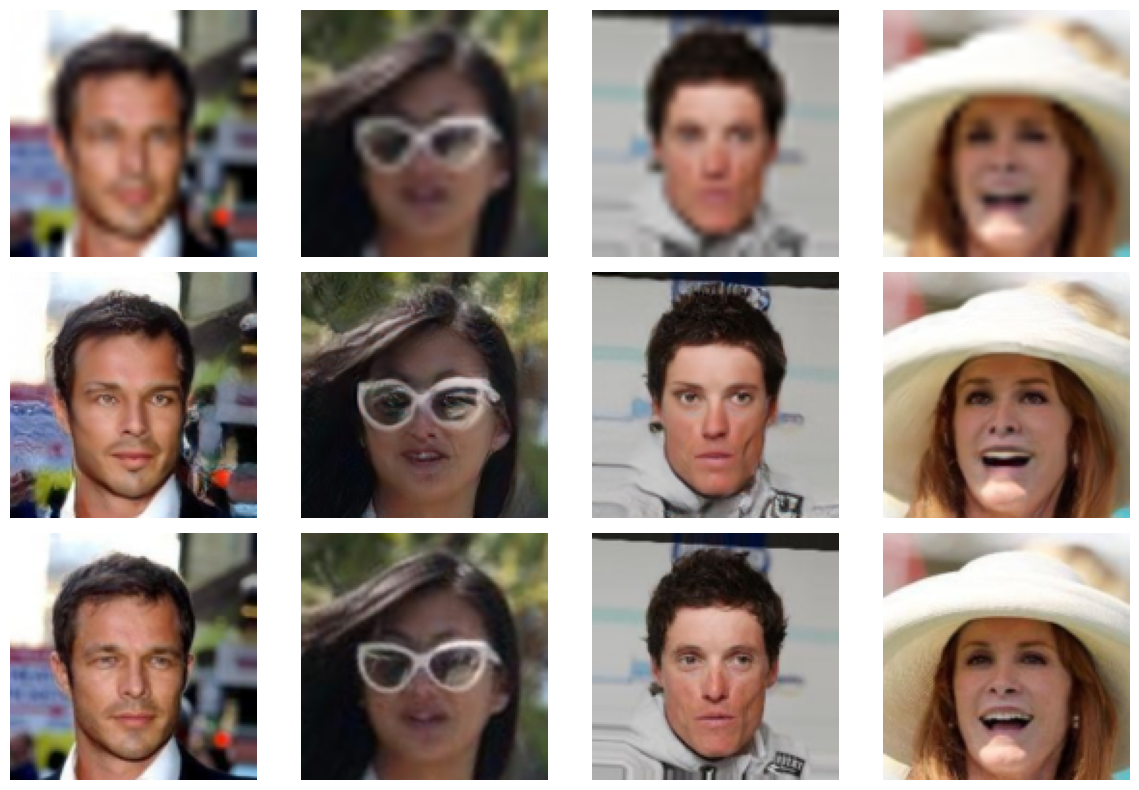

Saved checkpoint: /content/drive/MyDrive/AI_Notebooks/MGM/checkpoints/celeba_mgm_newexp/checkpoint_epoch_0010.pt

CUDA-event hours: 1.3518
CUDA-event seconds: 4866.4
Wall-clock hours: 1.3518


In [ ]:
EPOCHS = 10
LR_G = 1e-5
LR_F = 1e-5
LAMBDA_L1 = 0.0  # Pure MGM objective
EPS = 0.01

VALIDATION_EVERY = 5
CHECKPOINT_EVERY = 5

def sample_fn(generator_ema, epoch):
    save_sample_grid(
        generator=generator_ema,
        val_loader=val_loader,
        path=SAMPLES_PATH / f"celeba_epoch_{epoch:04d}.png",
        device=device,
        n_samples=4,
    )

meter = TimeMeter(device)

G, G_ema, opt_g, opt_f, history = train_mgm(
    generator=G,
    field=f,
    dataloader=train_loader,
    epochs=EPOCHS,
    lr_g=LR_G,
    lr_f=LR_F,
    lambda_l1=LAMBDA_L1,
    eps=EPS,
    device=device,
    max_grad_norm=1.0,
    ema_decay=0.999,
    val_dataloader=val_loader,
    val_max_batches=None,  # Full validation set
    f_warmup_checkpoint=warmup_checkpoint,  # load our warmed-up (f)
    checkpoint_dir=CHECKPOINTS_PATH,
    checkpoint_every=CHECKPOINT_EVERY,
    sample_fn=sample_fn,
    sample_every=VALIDATION_EVERY,
)

# Preserve the trained field variable for later notebook cells.
f = f

cost = meter.finish()

print(f"\nCUDA-event hours: {cost['gpu_hours']:.4f}")
print(f"CUDA-event seconds: {cost['gpu_seconds']:.1f}")
print(f"Wall-clock hours: {cost['wall_hours']:.4f}")

In [ ]:
HISTORY_PATH = Path(CHECKPOINTS_PATH).parent / "histories"
HISTORY_PATH.mkdir(parents=True, exist_ok=True)

# Save as CSV
csv_path = HISTORY_PATH / "exp3_celeba_history.csv"
history_df = pd.DataFrame(history)
history_df.to_csv(csv_path, index=False)

print(f"History saved to:\n{csv_path}")
print(f"Recorded epochs: {len(history)}")
print("Recorded metrics:", list(history_df.columns))

History saved to:
/content/drive/MyDrive/AI_Notebooks/MGM/checkpoints/histories/exp3_celeba_history.csv
Recorded epochs: 10
Recorded metrics: ['epoch', 'global_step', 'loss_f', 'loss_mgm', 'loss_l1', 'loss_g', 'val_l1', 'val_mse', 'val_ssim', 'val_psnr', 'val_outside_fraction']


### Training with k critic steps

In [ ]:
# Create fresh models
G = CelebAConditionalGenerator().to(device)
f = CelebAConditionalField().to(device)

Training conditional MGM | epochs 1–10 | paired updates/epoch: 208
Generator objective: mgm_loss_G returned value (preserving existing training convention).


  0%|          | 0/208 [00:00<?, ?it/s]

Epoch 1/10 | cycle 1/208 | global_step=1 | F_mean=0.00252 MGM=0.00009 L1=0.02726 | Grad_F_mean=0.062 Grad_G=0.123
Epoch 1/10 | cycle 51/208 | global_step=51 | F_mean=0.00127 MGM=0.00110 L1=0.02893 | Grad_F_mean=0.047 Grad_G=0.054
Epoch 1/10 | cycle 101/208 | global_step=101 | F_mean=0.00176 MGM=0.00063 L1=0.02854 | Grad_F_mean=0.041 Grad_G=0.085
Epoch 1/10 | cycle 151/208 | global_step=151 | F_mean=0.00146 MGM=0.00059 L1=0.02784 | Grad_F_mean=0.027 Grad_G=0.049
Epoch 1/10 | cycle 201/208 | global_step=201 | F_mean=0.00160 MGM=0.00052 L1=0.02571 | Grad_F_mean=0.052 Grad_G=0.058
EMA validation | L1=0.028146 | MSE=0.002307 | SSIM=0.8140 | PSNR=26.37 dB | outside [0,1]=2.59%


  0%|          | 0/208 [00:00<?, ?it/s]

Epoch 2/10 | cycle 1/208 | global_step=209 | F_mean=0.00102 MGM=0.00066 L1=0.02441 | Grad_F_mean=0.027 Grad_G=0.099
Epoch 2/10 | cycle 51/208 | global_step=259 | F_mean=0.00130 MGM=0.00089 L1=0.02751 | Grad_F_mean=0.049 Grad_G=0.061
Epoch 2/10 | cycle 101/208 | global_step=309 | F_mean=0.00104 MGM=0.00095 L1=0.02578 | Grad_F_mean=0.021 Grad_G=0.048
Epoch 2/10 | cycle 151/208 | global_step=359 | F_mean=0.00134 MGM=0.00065 L1=0.02725 | Grad_F_mean=0.041 Grad_G=0.075
Epoch 2/10 | cycle 201/208 | global_step=409 | F_mean=0.00129 MGM=0.00046 L1=0.02224 | Grad_F_mean=0.023 Grad_G=0.037
EMA validation | L1=0.027820 | MSE=0.002220 | SSIM=0.8188 | PSNR=26.54 dB | outside [0,1]=3.06%


...

Epoch 3/10 | cycle 1/208 | global_step=417 | F_mean=0.00146 MGM=0.00056 L1=0.02670 | Grad_F_mean=0.032 Grad_G=0.089
Epoch 3/10 | cycle 51/208 | global_step=467 | F_mean=0.00152 MGM=0.00056 L1=0.02770 | Grad_F_mean=0.041 Grad_G=0.052
Epoch 3/10 | cycle 101/208 | global_step=517 | F_mean=0.00115 MGM=0.00062 L1=0.02333 | Grad_F_mean=0.021 Grad_G=0.048
Epoch 3/10 | cycle 151/208 | global_step=567 | F_mean=0.00158 MGM=0.00046 L1=0.02663 | Grad_F_mean=0.034 Grad_G=0.030
Epoch 3/10 | cycle 201/208 | global_step=617 | F_mean=0.00135 MGM=0.00047 L1=0.02588 | Grad_F_mean=0.018 Grad_G=0.050
EMA validation | L1=0.026517 | MSE=0.002013 | SSIM=0.8296 | PSNR=26.96 dB | outside [0,1]=3.05%


  0%|          | 0/208 [00:00<?, ?it/s]

Epoch 4/10 | cycle 1/208 | global_step=625 | F_mean=0.00112 MGM=0.00050 L1=0.02510 | Grad_F_mean=0.027 Grad_G=0.028
Epoch 4/10 | cycle 51/208 | global_step=675 | F_mean=0.00128 MGM=0.00041 L1=0.02396 | Grad_F_mean=0.030 Grad_G=0.039
Epoch 4/10 | cycle 101/208 | global_step=725 | F_mean=0.00141 MGM=0.00077 L1=0.02862 | Grad_F_mean=0.026 Grad_G=0.086
Epoch 4/10 | cycle 151/208 | global_step=775 | F_mean=0.00111 MGM=0.00050 L1=0.02286 | Grad_F_mean=0.023 Grad_G=0.042
Epoch 4/10 | cycle 201/208 | global_step=825 | F_mean=0.00171 MGM=0.00046 L1=0.02909 | Grad_F_mean=0.038 Grad_G=0.080
EMA validation | L1=0.024975 | MSE=0.001782 | SSIM=0.8403 | PSNR=27.49 dB | outside [0,1]=2.79%


  0%|          | 0/208 [00:00<?, ?it/s]

Epoch 5/10 | cycle 1/208 | global_step=833 | F_mean=0.00125 MGM=0.00064 L1=0.02657 | Grad_F_mean=0.020 Grad_G=0.037
Epoch 5/10 | cycle 51/208 | global_step=883 | F_mean=0.00125 MGM=0.00046 L1=0.02471 | Grad_F_mean=0.021 Grad_G=0.024
Epoch 5/10 | cycle 101/208 | global_step=933 | F_mean=0.00134 MGM=0.00046 L1=0.02518 | Grad_F_mean=0.025 Grad_G=0.029
Epoch 5/10 | cycle 151/208 | global_step=983 | F_mean=0.00134 MGM=0.00053 L1=0.02559 | Grad_F_mean=0.033 Grad_G=0.052
Epoch 5/10 | cycle 201/208 | global_step=1033 | F_mean=0.00108 MGM=0.00054 L1=0.02305 | Grad_F_mean=0.015 Grad_G=0.041
EMA validation | L1=0.023916 | MSE=0.001634 | SSIM=0.8471 | PSNR=27.87 dB | outside [0,1]=2.41%


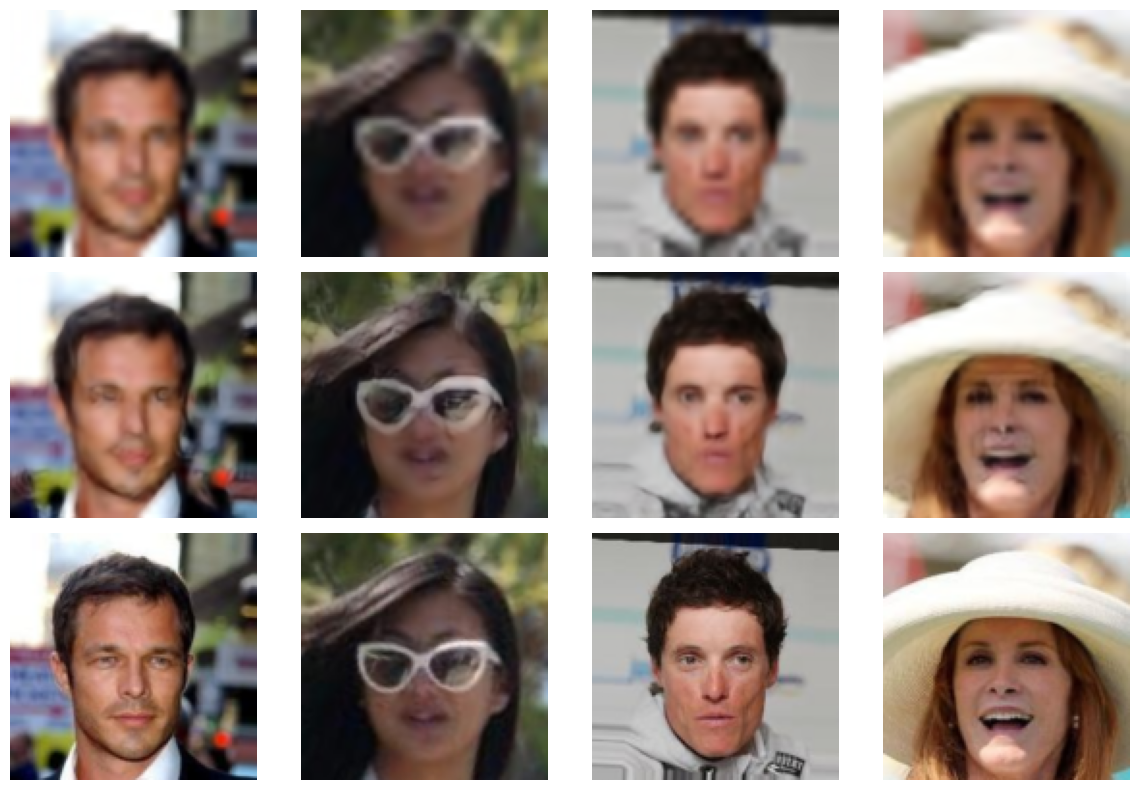

Saved checkpoint: /content/drive/MyDrive/AI_Notebooks/MGM/checkpoints/celeba_mgm_newexp/checkpoint_epoch_0005.pt


  0%|          | 0/208 [00:00<?, ?it/s]

Epoch 6/10 | cycle 1/208 | global_step=1041 | F_mean=0.00141 MGM=0.00046 L1=0.02531 | Grad_F_mean=0.031 Grad_G=0.038
Epoch 6/10 | cycle 51/208 | global_step=1091 | F_mean=0.00120 MGM=0.00044 L1=0.02495 | Grad_F_mean=0.018 Grad_G=0.026
Epoch 6/10 | cycle 101/208 | global_step=1141 | F_mean=0.00117 MGM=0.00044 L1=0.02328 | Grad_F_mean=0.017 Grad_G=0.030
Epoch 6/10 | cycle 151/208 | global_step=1191 | F_mean=0.00104 MGM=0.00072 L1=0.02437 | Grad_F_mean=0.020 Grad_G=0.036
Epoch 6/10 | cycle 201/208 | global_step=1241 | F_mean=0.00219 MGM=0.00049 L1=0.03046 | Grad_F_mean=0.066 Grad_G=0.074
EMA validation | L1=0.023433 | MSE=0.001567 | SSIM=0.8492 | PSNR=28.05 dB | outside [0,1]=2.07%


  0%|          | 0/208 [00:00<?, ?it/s]

Epoch 7/10 | cycle 1/208 | global_step=1249 | F_mean=0.00114 MGM=0.00040 L1=0.02417 | Grad_F_mean=0.028 Grad_G=0.049
Epoch 7/10 | cycle 51/208 | global_step=1299 | F_mean=0.00137 MGM=0.00062 L1=0.02806 | Grad_F_mean=0.019 Grad_G=0.058
Epoch 7/10 | cycle 101/208 | global_step=1349 | F_mean=0.00149 MGM=0.00051 L1=0.02568 | Grad_F_mean=0.024 Grad_G=0.033
Epoch 7/10 | cycle 151/208 | global_step=1399 | F_mean=0.00111 MGM=0.00043 L1=0.02432 | Grad_F_mean=0.014 Grad_G=0.044
Epoch 7/10 | cycle 201/208 | global_step=1449 | F_mean=0.00122 MGM=0.00062 L1=0.02321 | Grad_F_mean=0.018 Grad_G=0.038
EMA validation | L1=0.023309 | MSE=0.001550 | SSIM=0.8489 | PSNR=28.10 dB | outside [0,1]=1.81%


...

Epoch 8/10 | cycle 1/208 | global_step=1457 | F_mean=0.00149 MGM=0.00045 L1=0.02508 | Grad_F_mean=0.020 Grad_G=0.023
Epoch 8/10 | cycle 51/208 | global_step=1507 | F_mean=0.00177 MGM=0.00066 L1=0.02691 | Grad_F_mean=0.060 Grad_G=0.062
Epoch 8/10 | cycle 101/208 | global_step=1557 | F_mean=0.00143 MGM=0.00047 L1=0.02396 | Grad_F_mean=0.029 Grad_G=0.041
Epoch 8/10 | cycle 151/208 | global_step=1607 | F_mean=0.00139 MGM=0.00059 L1=0.02739 | Grad_F_mean=0.022 Grad_G=0.039
Epoch 8/10 | cycle 201/208 | global_step=1657 | F_mean=0.00143 MGM=0.00043 L1=0.02479 | Grad_F_mean=0.059 Grad_G=0.082
EMA validation | L1=0.023329 | MSE=0.001555 | SSIM=0.8479 | PSNR=28.08 dB | outside [0,1]=1.68%


  0%|          | 0/208 [00:00<?, ?it/s]

Epoch 9/10 | cycle 1/208 | global_step=1665 | F_mean=0.00121 MGM=0.00037 L1=0.02542 | Grad_F_mean=0.018 Grad_G=0.070
Epoch 9/10 | cycle 51/208 | global_step=1715 | F_mean=0.00101 MGM=0.00057 L1=0.02435 | Grad_F_mean=0.009 Grad_G=0.034
Epoch 9/10 | cycle 101/208 | global_step=1765 | F_mean=0.00127 MGM=0.00049 L1=0.02572 | Grad_F_mean=0.018 Grad_G=0.041
Epoch 9/10 | cycle 151/208 | global_step=1815 | F_mean=0.00100 MGM=0.00039 L1=0.02124 | Grad_F_mean=0.015 Grad_G=0.018
Epoch 9/10 | cycle 201/208 | global_step=1865 | F_mean=0.00120 MGM=0.00049 L1=0.02510 | Grad_F_mean=0.014 Grad_G=0.030
EMA validation | L1=0.023369 | MSE=0.001566 | SSIM=0.8472 | PSNR=28.05 dB | outside [0,1]=1.57%


  0%|          | 0/208 [00:00<?, ?it/s]

Epoch 10/10 | cycle 1/208 | global_step=1873 | F_mean=0.00113 MGM=0.00069 L1=0.02731 | Grad_F_mean=0.016 Grad_G=0.040
Epoch 10/10 | cycle 51/208 | global_step=1923 | F_mean=0.00110 MGM=0.00055 L1=0.02436 | Grad_F_mean=0.018 Grad_G=0.020
Epoch 10/10 | cycle 101/208 | global_step=1973 | F_mean=0.00112 MGM=0.00037 L1=0.02187 | Grad_F_mean=0.014 Grad_G=0.019
Epoch 10/10 | cycle 151/208 | global_step=2023 | F_mean=0.00137 MGM=0.00064 L1=0.02771 | Grad_F_mean=0.014 Grad_G=0.060
Epoch 10/10 | cycle 201/208 | global_step=2073 | F_mean=0.00086 MGM=0.00065 L1=0.02290 | Grad_F_mean=0.010 Grad_G=0.022
EMA validation | L1=0.023527 | MSE=0.001592 | SSIM=0.8453 | PSNR=27.98 dB | outside [0,1]=1.48%


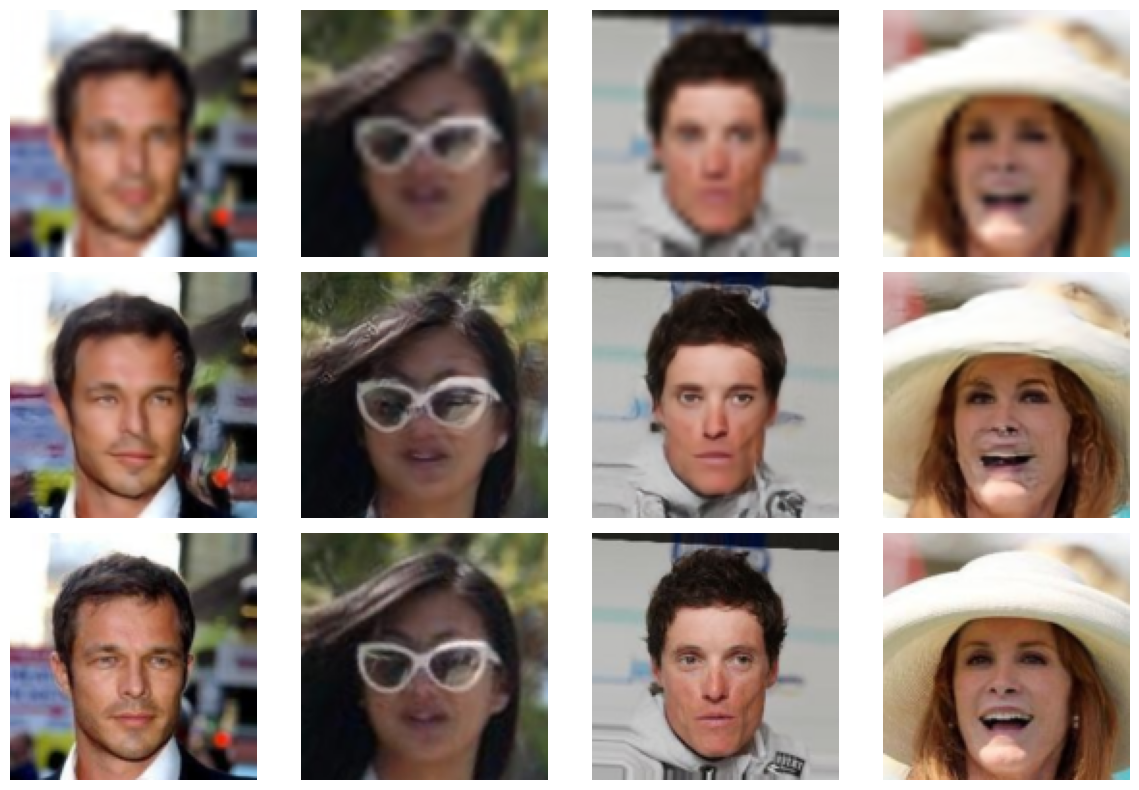

Saved checkpoint: /content/drive/MyDrive/AI_Notebooks/MGM/checkpoints/celeba_mgm_newexp/checkpoint_epoch_0010.pt

CUDA-event hours: 1.2361
CUDA-event seconds: 4449.9
Wall-clock hours: 1.2361


In [ ]:
EPOCHS = 10
LR_G = 1e-5
LR_F = 1e-5
LAMBDA_L1 = 0.0  # Pure MGM objective
EPS = 0.01

VALIDATION_EVERY = 5
CHECKPOINT_EVERY = 5

def sample_fn(generator_ema, epoch):
    save_sample_grid(
        generator=generator_ema,
        val_loader=val_loader,
        path=SAMPLES_PATH / f"celeba_epoch_{epoch:04d}.png",
        device=device,
        n_samples=4,
    )

meter = TimeMeter(device)

G, G_ema, opt_g, opt_f, history = train_mgm(
    generator=G,
    field=f,
    dataloader=train_loader,
    epochs=EPOCHS,
    lr_g=LR_G,
    lr_f=LR_F,
    lambda_l1=LAMBDA_L1,
    eps=EPS,
    device=device,
    max_grad_norm=1.0,
    ema_decay=0.999,
    val_dataloader=val_loader,
    val_max_batches=None,  # Full validation set
    # f_warmup_checkpoint=warmup_checkpoint,  # load our warmed-up (f)
    k_critic_steps=5,
    checkpoint_dir=CHECKPOINTS_PATH,
    checkpoint_every=CHECKPOINT_EVERY,
    sample_fn=sample_fn,
    sample_every=VALIDATION_EVERY,
)

# Preserve the trained field variable for later notebook cells.
f = f

cost = meter.finish()

print(f"\nCUDA-event hours: {cost['gpu_hours']:.4f}")
print(f"CUDA-event seconds: {cost['gpu_seconds']:.1f}")
print(f"Wall-clock hours: {cost['wall_hours']:.4f}")

In [ ]:
HISTORY_PATH = Path(CHECKPOINTS_PATH).parent / "histories"
HISTORY_PATH.mkdir(parents=True, exist_ok=True)

# Save as CSV
csv_path = HISTORY_PATH / "exp4_celeba_history.csv"
history_df = pd.DataFrame(history)
history_df.to_csv(csv_path, index=False)

print(f"History saved to:\n{csv_path}")
print(f"Recorded epochs: {len(history)}")
print("Recorded metrics:", list(history_df.columns))

History saved to:
/content/drive/MyDrive/AI_Notebooks/MGM/checkpoints/histories/exp4_celeba_history.csv
Recorded epochs: 10
Recorded metrics: ['epoch', 'global_step', 'loss_f', 'loss_mgm', 'loss_l1', 'loss_g', 'val_l1', 'val_mse', 'val_ssim', 'val_psnr', 'val_outside_fraction']


### More samples

Loaded EMA generator: checkpoint_epoch_0010.pt
Loaded EMA generator: checkpoint_epoch_0010.pt
Loaded EMA generator: checkpoint_epoch_0010.pt


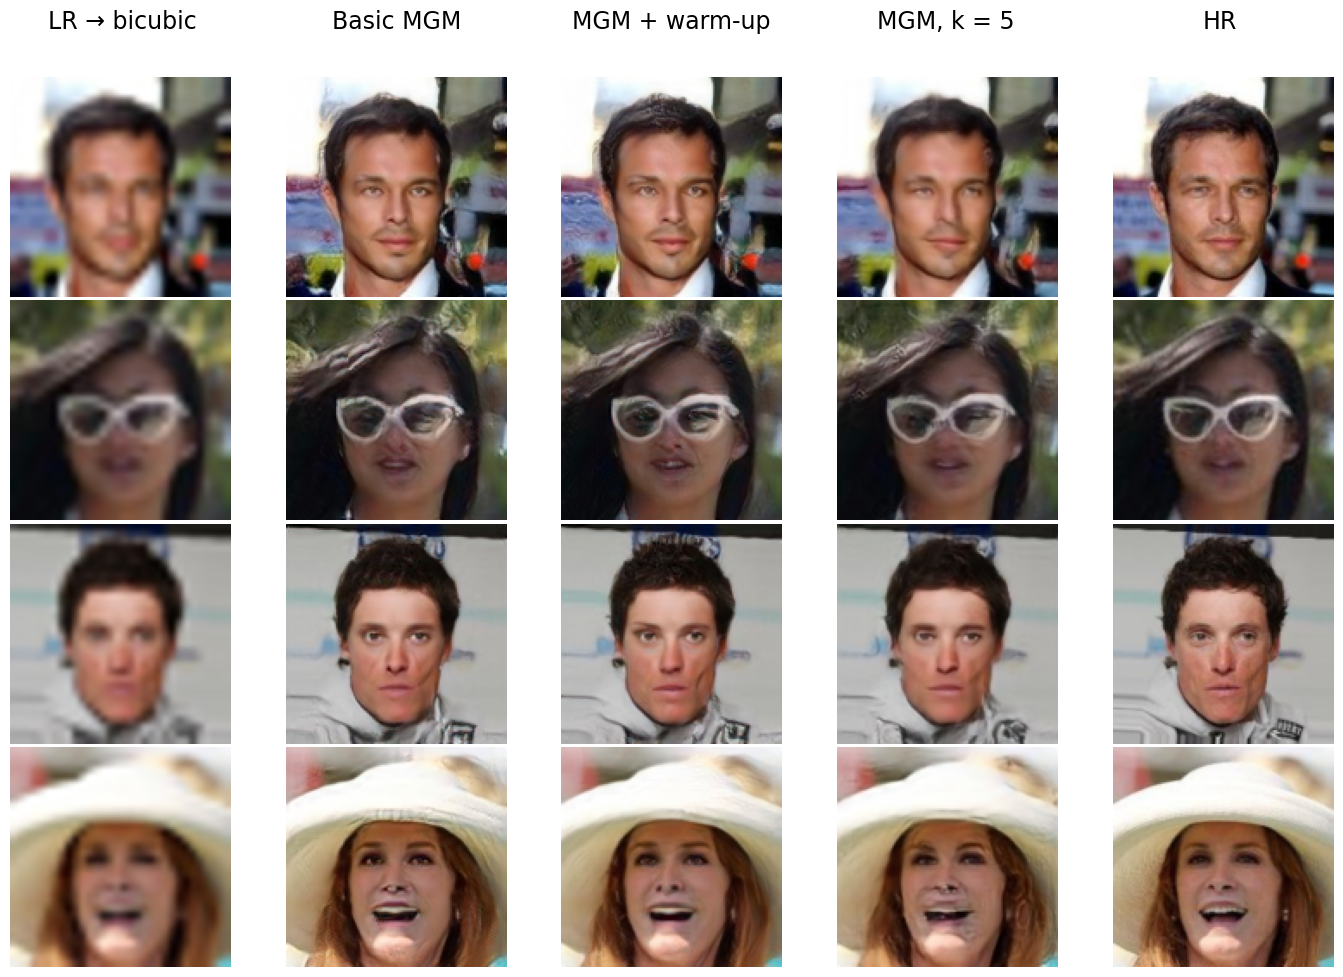

In [18]:

# ============================================================
# CelebA: fixed validation examples across all MGM methods
# ============================================================
import torch
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from pathlib import Path

# -------------------------
# 1. Configure checkpoints
# -------------------------
ALL_CHECKPOINTS_PATH = Path("/content/drive/MyDrive/AI_Notebooks/MGM/checkpoints")
BASIC_MGM_CHECKPOINT = ALL_CHECKPOINTS_PATH / "exp2_celeba_32to128" / "checkpoint_epoch_0010.pt"
WARMUP_MGM_CHECKPOINT = ALL_CHECKPOINTS_PATH / "exp3_celeba_32to128_warmup" / "checkpoint_epoch_0010.pt"
K5_MGM_CHECKPOINT = ALL_CHECKPOINTS_PATH / "exp4_celeba_32to128_5fsteps " / "checkpoint_epoch_0010.pt"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NUM_SAMPLES = 4

# -------------------------
# 2. Load generator weights
# -------------------------
# Assumes CelebAUNetGenerator(in_channels=3, out_channels=3)
# is already defined in your notebook.


def load_generator_checkpoint(model, checkpoint_path, device):
    checkpoint_path = Path(checkpoint_path)
    if not checkpoint_path.is_file():
        raise FileNotFoundError(
            f"Checkpoint not found: {checkpoint_path}"
        )

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False,
    )

    key = "generator_ema_state_dict"
    if key not in checkpoint:
        raise KeyError(
            f"'{key}' not found in {checkpoint_path.name}. "
            f"Available keys: {list(checkpoint.keys())}"
        )

    state_dict = checkpoint[key]
    state_dict = {
        k.removeprefix("module."): v
        for k, v in state_dict.items()
    }

    model.load_state_dict(state_dict, strict=True)
    model.to(device).eval()
    print(f"Loaded EMA generator: {checkpoint_path.name}")

    return model



# Instantiate three independent generators.
G_basic = CelebAConditionalGenerator()
G_warmup = CelebAConditionalGenerator()
G_k5 = CelebAConditionalGenerator()

G_basic = load_generator_checkpoint(
    G_basic, BASIC_MGM_CHECKPOINT, DEVICE
)
G_warmup = load_generator_checkpoint(
    G_warmup, WARMUP_MGM_CHECKPOINT, DEVICE
)
G_k5 = load_generator_checkpoint(
    G_k5, K5_MGM_CHECKPOINT, DEVICE
)

# -------------------------
# 3. Select fixed val images
# -------------------------
# Assumes val_loader yields (x_lr, x_hr), with tensors in [0, 1].
# Select the first five examples from one batch, so every row
# is based on precisely the same validation images.
val_iter = iter(val_loader)
x_lr, x_hr = next(val_iter)

x_lr = x_lr[:NUM_SAMPLES].to(DEVICE)
x_hr = x_hr[:NUM_SAMPLES].to(DEVICE)

assert x_lr.shape[0] == NUM_SAMPLES, (
    f"Need at least {NUM_SAMPLES} validation examples in the batch; "
    f"got {x_lr.shape[0]}."
)
assert x_hr.shape[0] == NUM_SAMPLES

# In this CelebA setup, x_lr is the bicubic-upsampled image at
# HR resolution (128x128), not the original small LR tensor.
assert x_lr.shape[-2:] == (128, 128), (
    f"Expected bicubic-upsampled LR images at 128x128, "
    f"got {tuple(x_lr.shape[-2:])}"
)
assert x_hr.shape[-2:] == (128, 128)

# -------------------------
# 4. Generate reconstructions
# -------------------------
with torch.inference_mode():
    pred_basic = G_basic(x_lr).clamp(0, 1)
    pred_warmup = G_warmup(x_lr).clamp(0, 1)
    pred_k5 = G_k5(x_lr).clamp(0, 1)

# Convert NCHW tensors to NHWC NumPy arrays for plotting.
def to_images(tensor):
    return (
        tensor.detach()
        .cpu()
        .permute(0, 2, 3, 1)
        .numpy()
    )

lr_images = to_images(x_lr)
basic_images = to_images(pred_basic)
warmup_images = to_images(pred_warmup)
k5_images = to_images(pred_k5)
hr_images = to_images(x_hr)





# -------------------------
# 5. Plot methods as columns
# -------------------------
method_labels = [
    "LR → bicubic",
    "Basic MGM",
    "MGM + warm-up",
    "MGM, k = 5",
    "HR",
]

# Each entry has shape (NUM_SAMPLES, H, W, C)
method_images = [
    lr_images,
    basic_images,
    warmup_images,
    k5_images,
    hr_images,
]

fig = plt.figure(figsize=(14, 10), frameon=False)

left_margin = 0.01
right_margin = 0.99
bottom_margin = 0.01
top_margin = 0.90  # leave room for captions

gs = fig.add_gridspec(
    nrows=NUM_SAMPLES,
    ncols=len(method_labels),
    left=left_margin,
    right=right_margin,
    bottom=bottom_margin,
    top=top_margin,
    wspace=0.025,  # small gap between methods
    hspace=0.015,  # very small gap between images
)

for c, (label, images) in enumerate(zip(method_labels, method_images)):
    # Caption centered above each method's image column
    x_center = left_margin + (c + 0.5) * (
        (right_margin - left_margin) / len(method_labels)
    )
    fig.text(
        x_center,
        0.955,
        label,
        ha="center",
        va="center",
        fontsize=17,
        fontweight="normal",
    )

    for r in range(NUM_SAMPLES):
        ax = fig.add_subplot(gs[r, c])
        ax.imshow(images[r].clip(0, 1), aspect="equal")
        ax.set_axis_off()

plt.show()

# Optional export:
# fig.savefig(
#     "celeba_all_methods_columns.png",
#     dpi=250,
#     bbox_inches="tight",
#     pad_inches=0.01,
# )



# Optional export with no padding:
# fig.savefig(
#     "celeba_all_methods_tight_grid.png",
#     dpi=250,
#     bbox_inches="tight",
#     pad_inches=0,
# )


# Optional high-resolution export:
# fig.savefig("celeba_mgm_validation_grid.png",
#             dpi=250, bbox_inches="tight")


In [30]:

import random
import torch
import matplotlib.pyplot as plt

NUM_SAMPLES = 16
DEVICE = next(G_warmup.parameters()).device

# Collect validation images
all_lr = []
for x_lr_batch, _ in val_loader:
    all_lr.append(x_lr_batch)

all_lr = torch.cat(all_lr, dim=0)

assert len(all_lr) >= NUM_SAMPLES, (
    f"Need at least {NUM_SAMPLES} validation images; "
    f"found {len(all_lr)}."
)

# Randomly select 16 distinct examples
indices = random.sample(range(len(all_lr)), NUM_SAMPLES)
x_lr = all_lr[indices].to(DEVICE)

# Generate reconstructions using the warm-up EMA generator
G_warmup.eval()
with torch.inference_mode():
    x_pred = G_warmup(x_lr).clamp(0, 1)

def to_images(tensor):
    return (
        tensor.detach()
        .cpu()
        .permute(0, 2, 3, 1)
        .numpy()
    )

lr_images = to_images(x_lr)
pred_images = to_images(x_pred)

# Layout:
# Row 1: inputs  1–8
# Row 2: outputs 1–8
# Row 3: inputs  9–16
# Row 4: outputs 9–16
fig, axes = plt.subplots(
    4, 8,
    figsize=(20, 10),
    gridspec_kw={"wspace": 0.005, "hspace": 0.005},
)

for j in range(8):
    # First group of 8
    axes[0, j].imshow(lr_images[j].clip(0, 1))
    axes[1, j].imshow(pred_images[j].clip(0, 1))

    # Second group of 8
    axes[2, j].imshow(lr_images[j + 8].clip(0, 1))
    axes[3, j].imshow(pred_images[j + 8].clip(0, 1))

for ax in axes.flat:
    ax.set_axis_off()

plt.subplots_adjust(
    left=0, right=1,
    top=1, bottom=0,
    wspace=0.005, hspace=0.005,
)

plt.show()

# Optional export:
# fig.savefig(
#     "celeba_warmup_16_samples.png",
#     dpi=250, bbox_inches="tight", pad_inches=0
# )



Output hidden; open in https://colab.research.google.com to view.